# Fitting S-D model

Includes:
- Fitting to early time clonal data implies bias to symmetric fate outcome
- Fitting to all times, shown with 2 different metrics, marginal distribution, and "full distribution" (joint distribution broken down into S-like and D-like)

See Extended Data Fig. 3 and Supplementary Theory

Before running analysis scripts the fitting scripts must be run on a cluster, this will take a long time so is not feasible on a personal computer.

## Early-time clonal data
To fit early-time clonal data with SD model run: [FitSD_early_fits.py](../../modelling/FitSD_early_fits.py):

```bash
#Run command:
parallel --max-procs 40 python3.12 SD_early_fits.py {1} 1 0 0 ::: {0..20000} &
parallel --max-procs 40 python3.12 SD_early_fits.py {1} 1 0 1 ::: {0..20000} &
parallel --max-procs 40 python3.12 SD_early_fits.py {1} 1 0 2 ::: {0..20000} &

#Combine simulations:
python3.12 SD_early_fits.py -1 1 0 0 &
python3.12 SD_early_fits.py -1 1 0 1 &
python3.12 SD_early_fits.py -1 1 0 2 &
```

## Fit clonal data with 0D model
To fit full clonal data with 0D SD model run: [FitSD0D.py](../../modelling/FitSD0D.py):

```bash
#Run sweep with:
parallel --max-procs 50 python3.12 FitSD0D.py {1} 1 0 0 ::: {0..22000} & #M, SD
parallel --max-procs 50 python3.12 FitSD0D.py {1} 1 0 1 ::: {0..22000} & #F, SD

#Combine sims with:
python3.12 FitSD0D.py -1000 1 0 0 &
python3.12 FitSD0D.py -1000 1 0 1 &


#Run parallel simulated annealing with:
parallel --max-procs 40 python3.12 FitSD0D.py {1} 1 0 0 ::: {-40..-1} & #M, SD
parallel --max-procs 40 python3.12 FitSD0D.py {1} 1 0 1 ::: {-40..-1} & #F, SD

#Combine sim anneal simulations with:
python3.12 FitSD0D.py -2000 1 0 0 &
python3.12 FitSD0D.py -2000 1 0 1 &

```


## Fit clonal data with 2D model
To fit full clonal data with 2D SD model run: [FitSD2D_full.py](../../modelling/FitSD2D_full.py):

```bash
#Run sweep with:
parallel --max-procs 12 python3.12 FitSD2D_full.py.py {1} 1 0 0 ::: {0..22000} & #M, SD
parallel --max-procs 12 python3.12 FitSD2D_full.py.py {1} 1 0 1 ::: {0..22000} & #F, SD

#Combine sims with:
python3.12 FitSD2D_full.py.py -1000 1 0 0 &
python3.12 FitSD2D_full.py.py -1000 1 0 1 &


#Run parallel simulated annealing sweeps with:
parallel --max-procs 40 python3.12 FitSD2D_full.py.py {1} 1 0 0 ::: {-40..-1} & #M, SD
parallel --max-procs 40 python3.12 FitSD2D_full.py.py {1} 1 0 1 ::: {-40..-1} & #F, SD

#Combine sim anneal simulations with:
python3.12 FitSD2D_full.py.py -2000 1 0 22 &
python3.12 FitSD2D_full.py.py -2000 1 0 23 &

```



In [ ]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.append("../../analysis/")
sys.path.append("../../sim/")
sys.path.append("../../fit/")
sys.path.append("../../plot/")



from tissue import *
import tissplot as tplt
import matplotlib.path as mplPath
import datasets as ds 
import tiss_optimize as topt
import custom_metrics as cmet
import sim_model

from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 10
rcParams['axes.labelweight'] = 'normal'
rcParams['xtick.labelsize'] = 7.5
rcParams['ytick.labelsize'] = 7.5
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 7.5  # General font size
rcParams['text.usetex'] = False
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5



# Early time clonal data

Fitting the joint distribution of early time-points (see Supplementary Note)



Model: SD_0D
1 0 22
Chopping data with t > 30
dan_2410_ctr_M.pkl 827.7247020298914 joint1
Best fit: index                                                              13023
CVd_S                                                                0.3
CVd_D                                                                0.4
corrSS                                                               0.1
r                                                                    0.4
rho                                                                 0.55
tau                                                                100.0
corrSD                                                               0.0
corrDD                                                               0.0
maxseed                                                                0
dists0                                                        253.584092
dists0:shed                                                         -0.2
dists0:tscale         

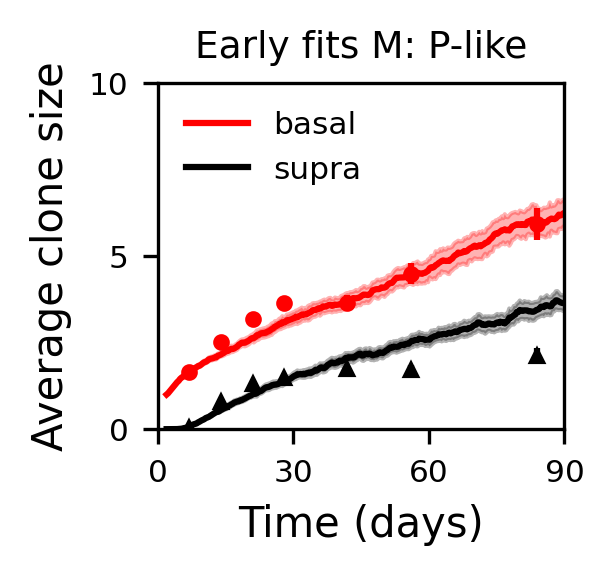

Already cropped
Already cropped


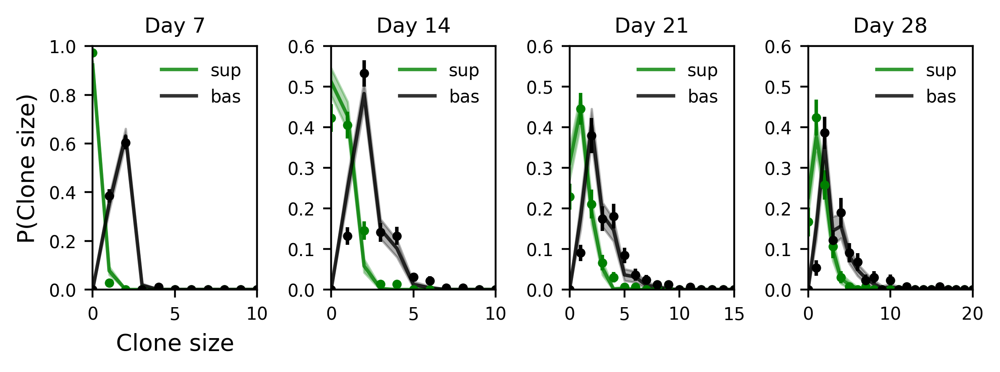

Already cropped


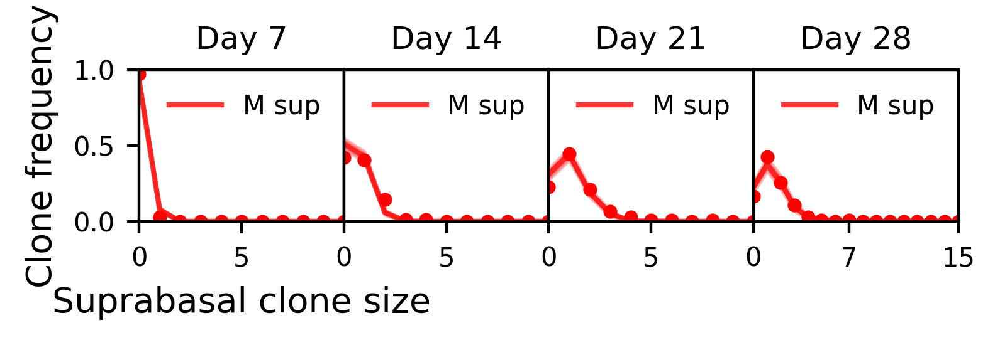

Already cropped


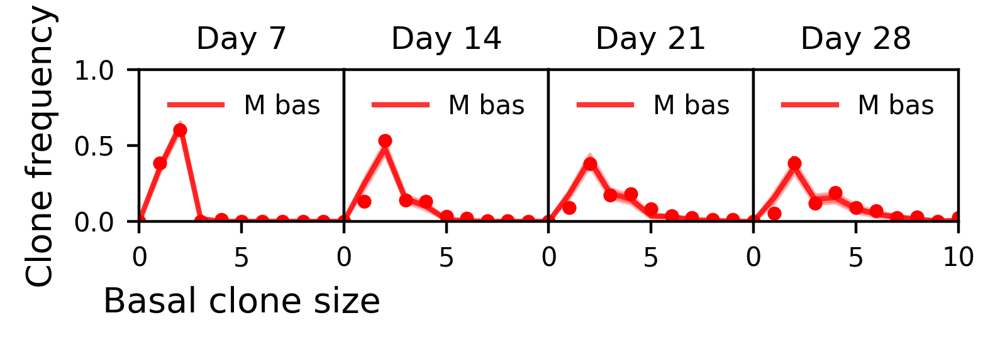

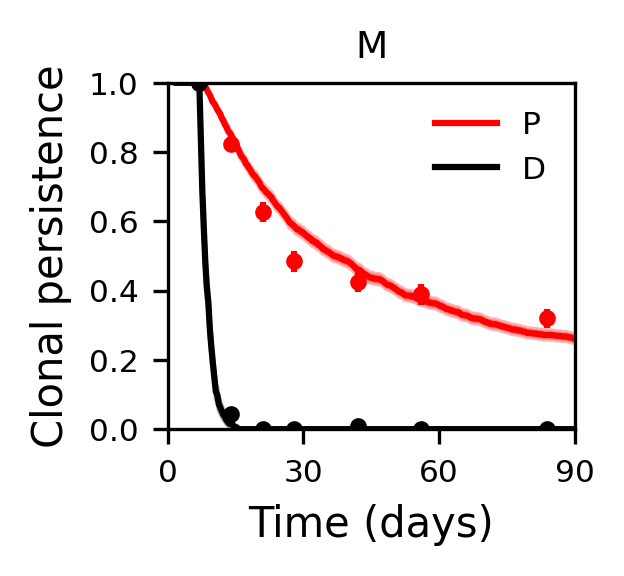






Model: SD_0D
1 0 23
Chopping data with t > 30
dan_2410_ctr_F.pkl 1865.38264035184 joint1
Best fit: index                                                               7038
CVd_S                                                                0.4
CVd_D                                                                0.9
corrSS                                                               0.1
r                                                                    0.8
rho                                                                  0.4
tau                                                                100.0
corrSD                                                               0.0
corrDD                                                               0.0
maxseed                                                                0
dists0                                                        516.074746
dists0:shed                                                         -0.2
dists0:tscale       

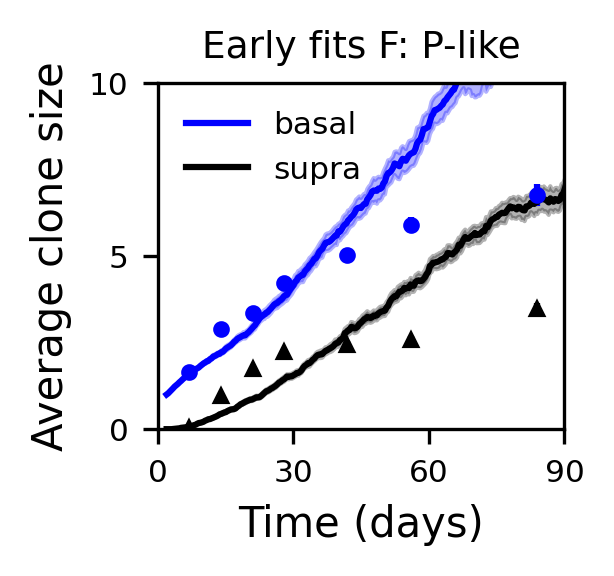

Already cropped
Already cropped


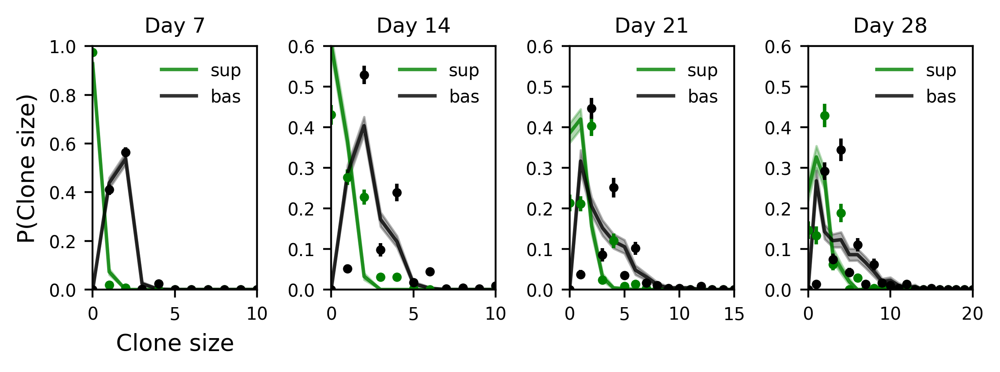

Already cropped


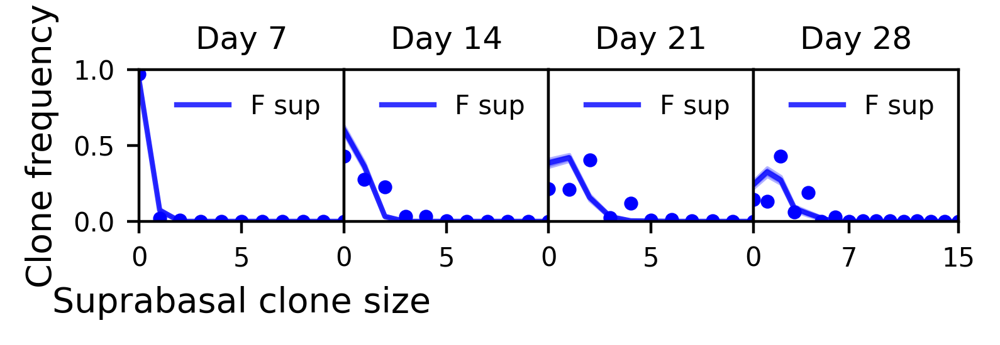

Already cropped


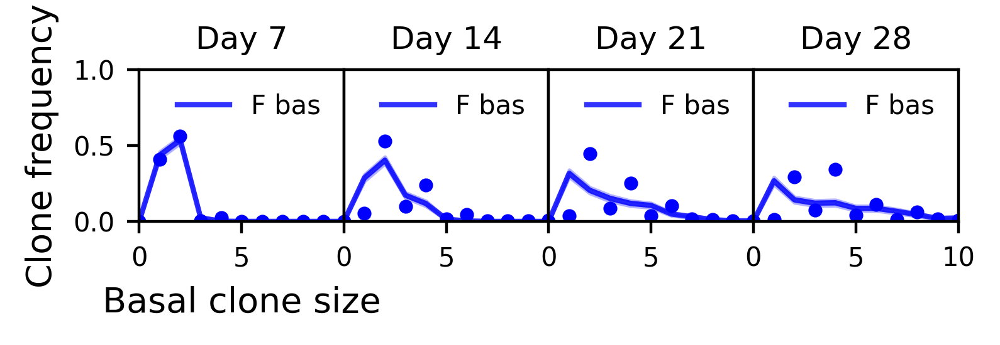

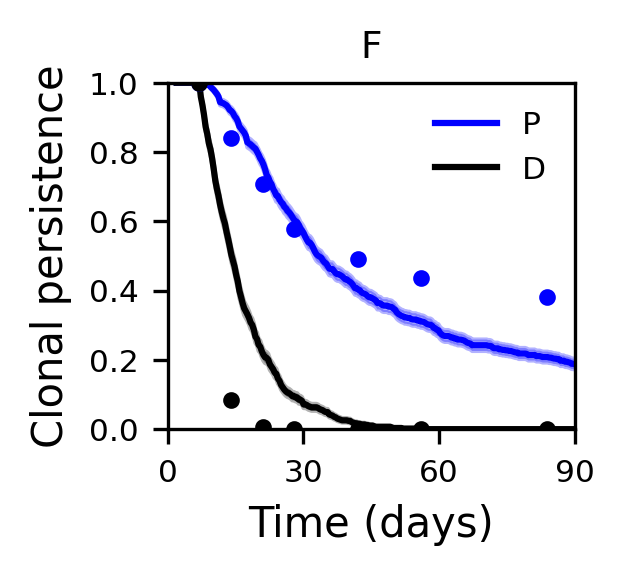

In [ ]:

#Metrics
means  = {'quantity': ['basalCS', 'supraCS', 'S2like.pers', 'Dlike.pers'], 'qmetric': 'lLLnb', 'name': 'means', 'exclude_times': {'basalCS': [0,1,2], 'supraCS': [0,1,2]}}
dists  = {'dist': ['basalCS', 'supraCS'], 'dist_metric': 'lLL', 'name': 'dists', 'exclude_times': {'basalCS': [0,1,2], 'supraCS': [0,1,2]}}
ksdists  = {'dist': ['S2like.basalCS', 'S2like.supraCS'], 'dist_metric': 'ksd', 'name': 'ksd_b_sb'}
k1dists  = {'dist': ['S2like.basalCS'], 'dist_metric': 'ksd', 'name': 'ksd_bas'}
joints = {'custom_metrics': {'jointCS': cmet.logLL_joint}, 'name': 'joint'}
full = {'custom_metrics': {'S2like.fulljointCS': cmet.logLL_joint, 'Dlike.fulljointCS': cmet.logLL_joint}, 'name': 'full'}#, 'exclude_times': {'S2like.jointCS': [0,1,2]}}
Dlo = {'custom_metrics': {'Dlike.fulljointCS': cmet.logLL_joint}, 'name': 'Dlo'}
trans  = {'custom_metrics': {'btranCS': cmet.logLL_move_bas, 'tranCS': cmet.logLL_move_sb}, 'name': 'trans'}
xf = {'dist': ['S2like.xfrac'], 'dist_metric': 'lLL', 'name': 'xf'}
mets = [full, means, dists, k1dists, joints, Dlo, xf]


dataset = ['data_ctr_M.pkl',    'data_ctr_F.pkl', 
                'data_castre.pkl', 'data_Ovx.pkl', 
                'data_Lgr6_M.pkl', 'data_Lgr6_F.pkl',
                'data_Notch1_M.pkl', 'data_Notch1_F.pkl']

ncores = 1


met = 'full'
best_fits = {}
#Metrics
dists0  = {'dist': ['S2like.basalCS', 'S2like.supraCS'], 'dist_metric': 'lLL', 'name': 'dists0', 
        'exclude_times': {'S2like.basalCS': np.arange(1,8), 'S2like.supraCS': np.arange(1,8)}}
joints0 = {'custom_metrics': {'S2like.jointCS': cmet.logLL_joint}, 'name': 'joint0',
           'exclude_times': {'S2like.jointCS': np.arange(1,8)}}
dists1  = {'dist': ['S2like.basalCS', 'S2like.supraCS'], 'dist_metric': 'lLL', 'name': 'dists1', 
        'exclude_times': {'S2like.basalCS': np.arange(2,8), 'S2like.supraCS': np.arange(2,8)}}
joints1 = {'custom_metrics': {'S2like.jointCS': cmet.logLL_joint}, 'name': 'joint1',
           'exclude_times': {'S2like.jointCS': np.arange(2,8)}}

mets = [dists0, joints0, dists1, joints1]

model = {0: 'SD_0D', 1: 'STD_0D', 2: 'S_0D', 3: 'SPD_0D', 4: 'ST2D_0D'}
toCalculate = ['S2like.pers', 'Dlike.pers']
compute_kwargs = {}


sexname = {'M': 'M', 'F': 'F', 'castre': 'cM'}

sexes = {0: 'M', 1: 'F', 2: 'castre'}
cols = {'M': 'r', 'F': 'b', 'castre': 'purple'}

figsavefolder = 'SFig4_SD_model/F4_'


for didx in [0, 1]:
    sex = sexes[didx]
    for mode in [0]:
        print('\n\nModel:', model[mode])
        if didx < 2:
            exp_file = '../experiment/homeo/' + dataset[didx]
        elif didx == 2:
            exp_file = '../experiment/castre/' + dataset[didx]
        elif didx == 3:
            exp_file = '../experiment/ovx/' + dataset[didx]    
        elif didx  < 6:
            exp_file = '../experiment/lgr6/' + dataset[didx]    
        elif didx < 8:
            exp_file = '../experiment/notch/' + dataset[didx]    
        else:
            assert(0)
            
        print(ncores, mode, didx)

        #Set-up optimiser
        tscale_quant = 'S2like.basalCS'
        savefolder = '../0D_gamma/short_SD0D/'
        s0 = topt.optimizer(sim_model.SD_0D, {'CVd_S':  np.arange(0.1, 1.01, 0.1),
                                            'CVd_D':  np.arange(0.1, 1.01, 0.1),
                                            'corrSS': np.arange(0.1, 1.01, 0.1),
                                            'r':      np.arange(0.1,1.01, 0.1),
                                            'rho': [0.4,0.6]},
                            params = {'tau': 100.0, 'corrSD': 0.0, 'corrSD': 0.0, 'corrDD': 0.0}, 
                            simtype = 'h', exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                        compute_kwargs = compute_kwargs, toCalculate = toCalculate)
        
        exp_data = s0.exp_data
        s0 = topt.optimizer(sim_model.SD_0D, {'CVd_S':  np.arange(0.1, 1.01, 0.1),
                                            'CVd_D':  np.arange(0.1, 1.01, 0.1),
                                            'corrSS': np.arange(0.1, 1.01, 0.1),
                                            'r':      np.arange(0.1,1.01, 0.1),
                                            'rho': [0.4,0.6]},
                            params = {'tau': 100.0, 'corrSD': 0.0, 'corrSD': 0.0, 'corrDD': 0.0}, 
                            simtype = 'h', exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                        compute_kwargs = compute_kwargs, max_time = 30, toCalculate = toCalculate)        
    
        s0.load_existing(tsteps = 1000, ncells = 1000, savefolder = savefolder, 
                        tscalevals = -np.arange(2,15,0.05),
                        shedvals = -np.arange(0.2, 1.5, 0.1), 
                        postopt_params = {'sbas_cv': np.arange(0.1, 1.01, 0.1)}, )
        s0.searchspace = s0.searchspace[np.array([~np.isnan(b) for b in s0.searchspace['joint1:sbas_cv']])]
        s0.searchspace = s0.searchspace[s0.searchspace['corrSS'] == 0.1]
        s0.searchspace = s0.searchspace.reset_index(drop = True)

        
        for met in ['joint1']:
            print(dataset[didx], s0.searchspace[met].min(), met)

            best_fits[(savefolder, dataset[didx], met)] = s0.best_fit(met)
            
            if s0.searchspace[met].min() >= 1e10:
                print('Missing fit')
                assert(0)
                continue
            
            #continue
            sim_data = s0.get_best_fit(met, 5000, 2000, savefolder = savefolder, nseeds = 1, save_results = True, skip = 5, print_fit = True, norun = False)
            #exp_data = s0.exp_data

            print('\n Best joint distribution fit')
            print(s0.boot_stats(met).to_string(float_format=lambda x: f"{x:.3f}"))

            plt.figure(figsize = (1.75,1.5), dpi = 300)  
            ds.plot_quantity('S2like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('S2like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Average clone size', plot_seeded = False, bootSEs = True, prelabel = 'supra', color = 'k', xfmt = '^', sfmt = '-')
            plt.xlim([0,90])
            plt.ylim([0,10])
            #plt.yticks(np.arange(0, 15, 1),minor = True)
            plt.yticks([0,5,10])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False, loc = 'upper left')
            plt.title('Early fits ' + sex + ': P-like')
            plt.xlim([0,90])
            plt.show() 


            sdt = sim_data.data_time_crop()
            #assert(0)

            axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes= [0,1,2,3], maxbin = 25, cdf = False, xlabel= 'Clone size', prelabel= 'sup', bootSEs=True, color = 'g', ncols=4, im_width = 1.5)
            axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes= [0,1,2,3], maxbin = 25, cdf = False, xlabel= 'Clone size', prelabel= 'bas', bootSEs=True, color = 'k', subplot_axs = axs, ncols=4,
                               im_width = 1.5, ymax = [1.0, 0.6, 0.6, 0.6], xmax = [10, 10, 15, 20])
            
            plt.savefig('Figures/SFig4_SD_model/' + dataset[didx] + '_early_dist.pdf', dpi = 400)
            plt.show()

            axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes = np.array([0,1,2,3]), maxbin = 25, cdf = False, 
                        xlabel= 'Suprabasal clone size', prelabel= f'{sexname[sex]} sup', bootSEs=True, color = f'{cols[sex]}', 
                            ncols=4, im_width = 1.0, ymax = 1.0, xmax = [10,10,10,15],
                            ylabel = 'Clone frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True, 
                            yticks = [0,0.5,1.0])
            plt.savefig('Figures/SFig4_SD_model/' + dataset[didx] + '_early_dist.pdf', dpi = 400)
            plt.show()

            axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes = np.array([0,1,2,3]), maxbin = 25, cdf = False, 
                                xlabel= 'Basal clone size', prelabel= f'{sexname[sex]} bas', bootSEs=True, color = f'{cols[sex]}',
                            ncols=4, im_width = 1.0, ymax = 1.0, xmax = [10,10,10,10],
                            ylabel = 'Clone frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True,
                            yticks = [0,0.5,1.0])           
            plt.savefig('Figures/SFig4_SD_model/' + dataset[didx] + '_early_dist.pdf', dpi = 400)
            plt.show()


            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S2like.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'P', color = cols[sex])
            ds.plot_quantity('Dlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Clonal persistence', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(dataset[didx])
            plt.xlim([0,90])
            plt.ylim([0,1])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_early_persistence.pdf', dpi = 300)
            plt.show() 


            print('\n\n')
            
            continue
        


# Fits to profile of clonal dynamics

Using an S-D model we aim to fit the full profile of clonal dynamics



Model: SD_0D
1 0 22
dan_2410_ctr_M.pkl 1.8958367713226547 ksd_b_sb
hrun_SD_0D_t_25000_n_4000_CVd_D_0.4_CVd_S_0.25_corrDD_0.0_corrSD_0.0_corrSS_0.0_r_0.4_rho_0.6_tau_500.0_seed_0.pkl
tscale: -5.65
τ range: 2.7600000000000002 to 70.0
shed: -0.7 refract: 0.0 cv: 0.5
Already cropped
Already cropped
Already cropped
Already cropped


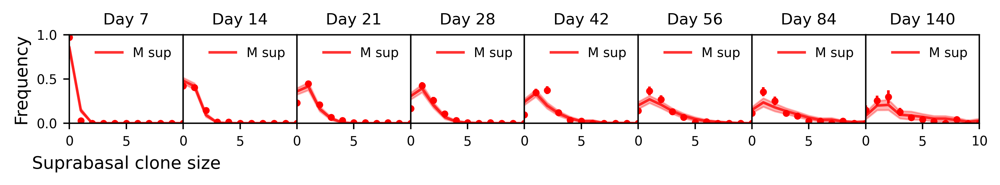

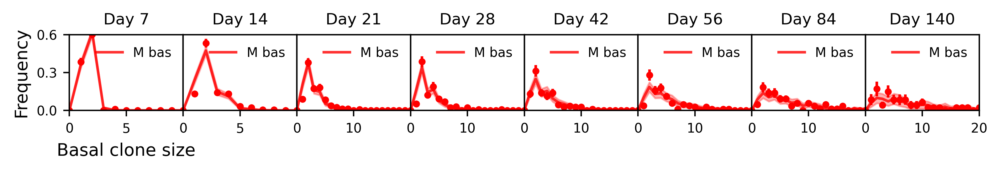

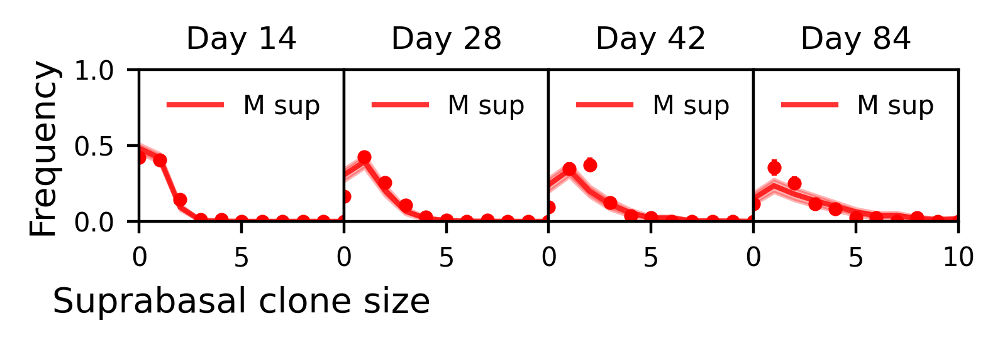

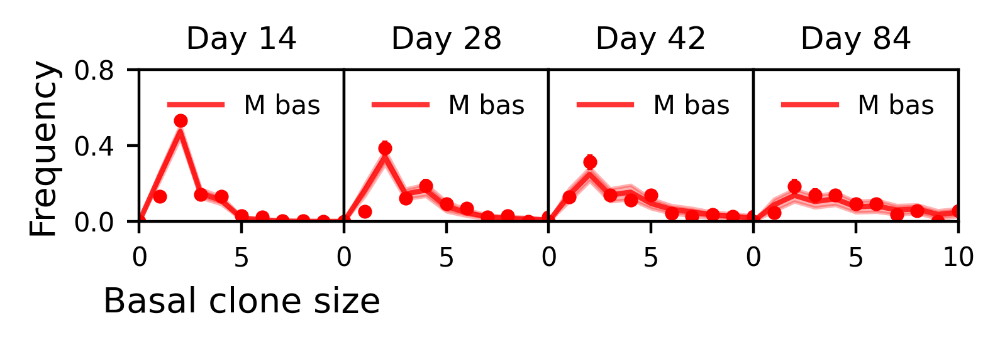

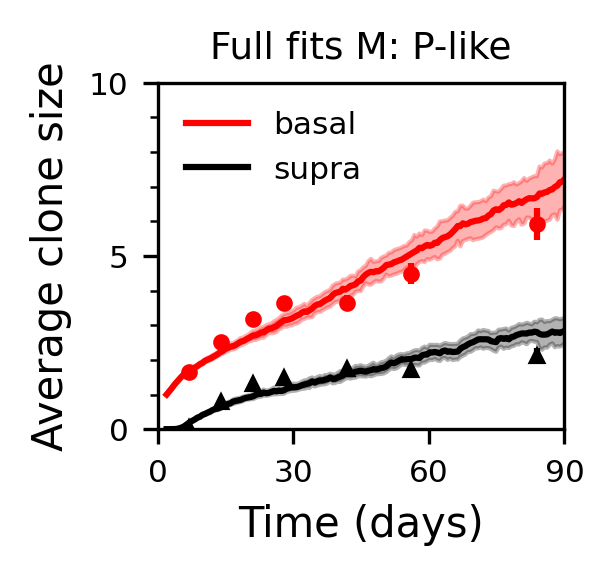

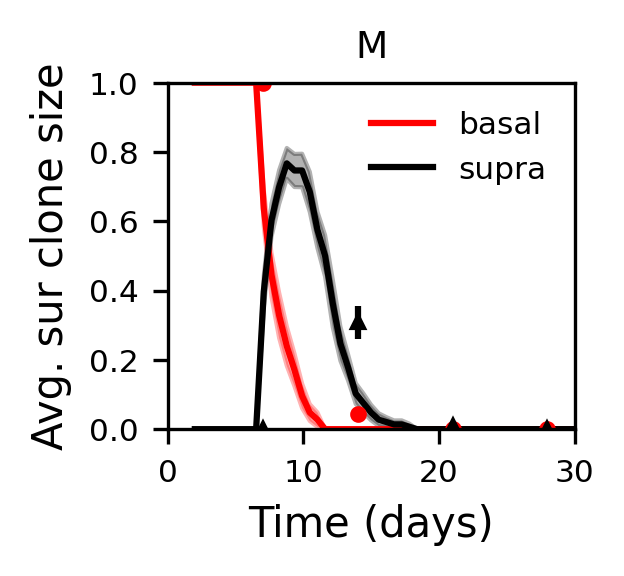

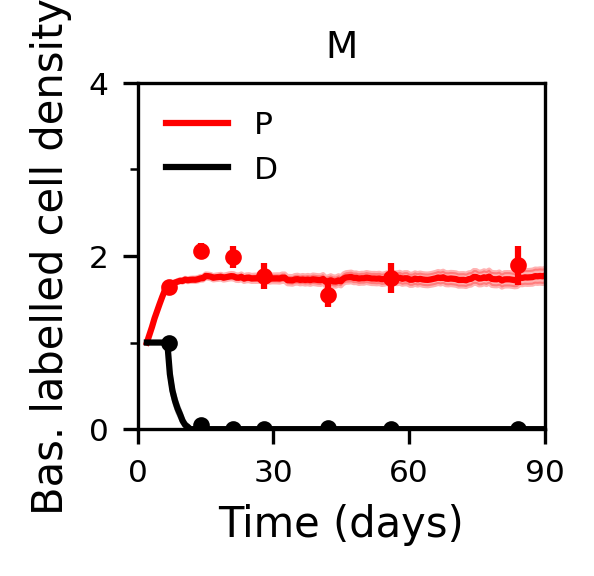

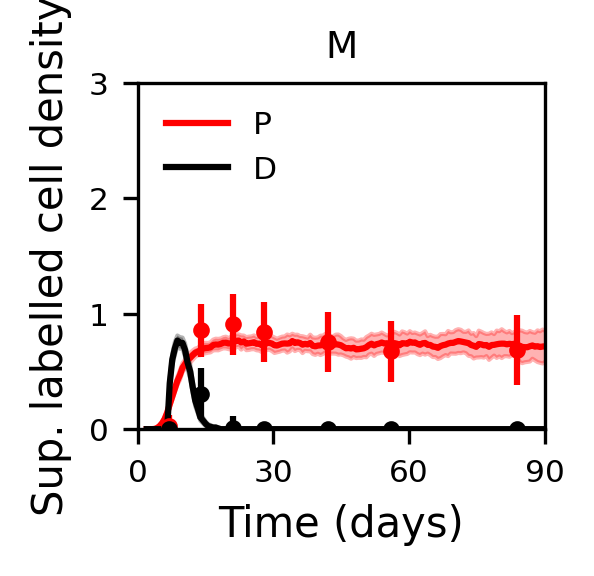

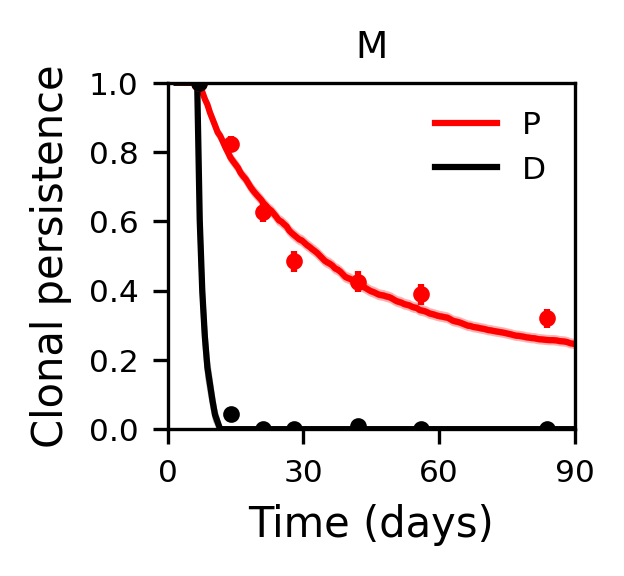






Model: SD_0D
1 0 23
dan_2410_ctr_F.pkl 2.0035131753916215 ksd_b_sb
hrun_SD_0D_t_25000_n_4000_CVd_D_0.4_CVd_S_0.55_corrDD_0.0_corrSD_0.0_corrSS_0.0_r_0.3_rho_0.4_tau_500.0_seed_0.pkl
tscale: -4.8
τ range: 2.7600000000000002 to 70.0
Starting sim with 4000 cells at Sun Apr 13 18:26:15 2025
Ending sim with 4231 cells at Sun Apr 13 18:26:28 2025
Resetting time and division times
Starting sim with 4231 cells at Sun Apr 13 18:26:30 2025
Ending sim with 4411 cells at Sun Apr 13 18:32:27 2025
shed: -1.3 refract: 0.0 cv: 0.1
Already cropped
Already cropped
Already cropped
Already cropped


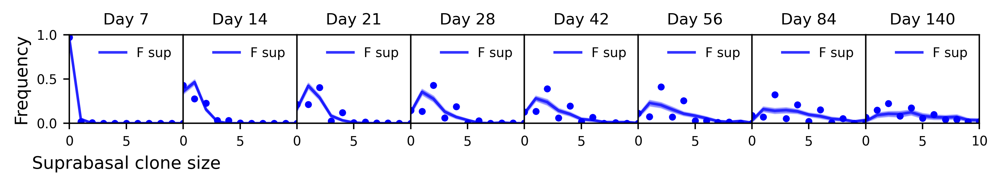

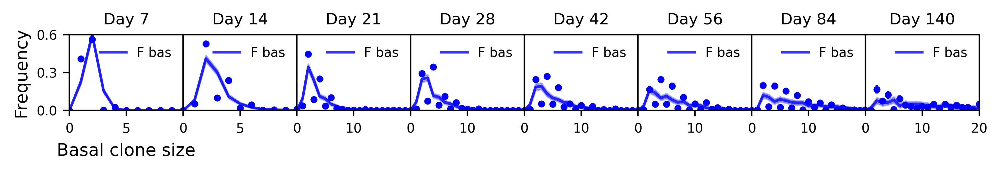

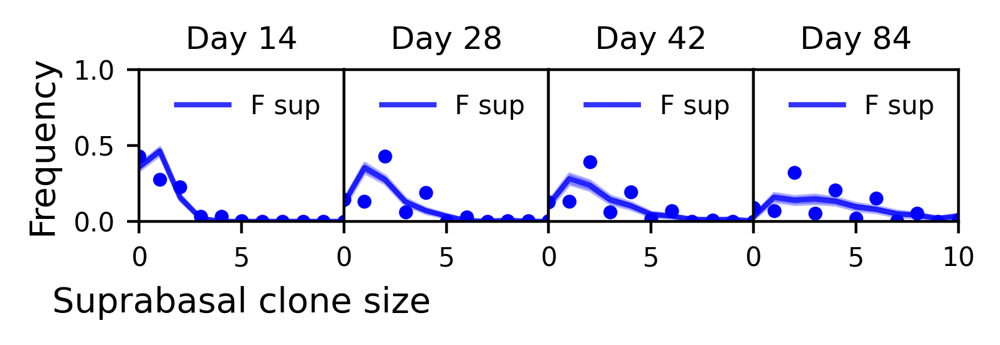

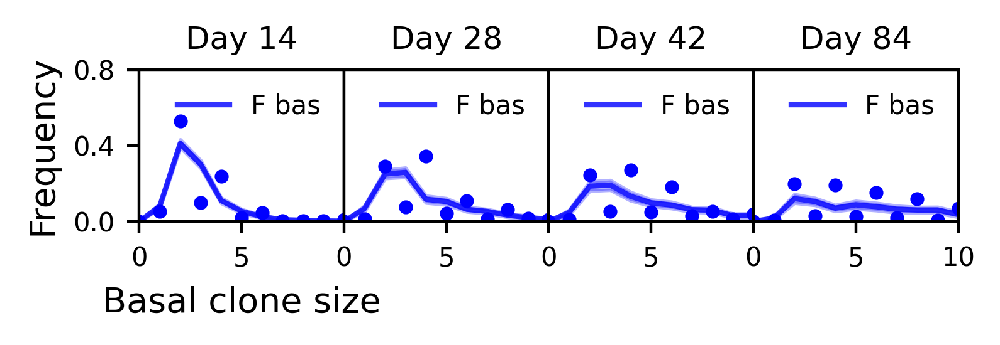

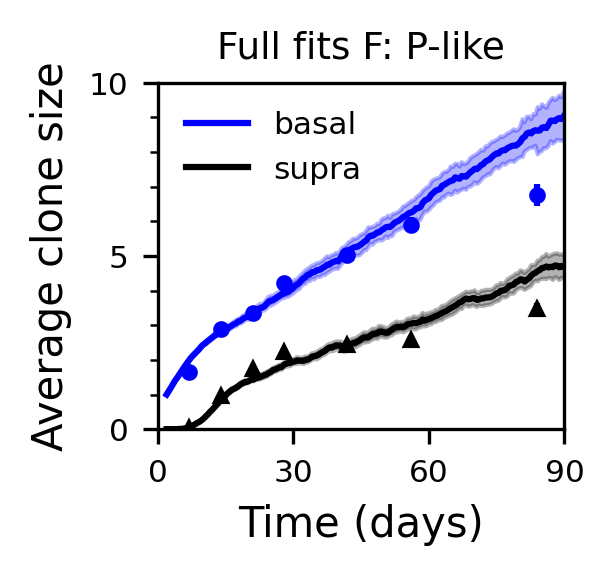

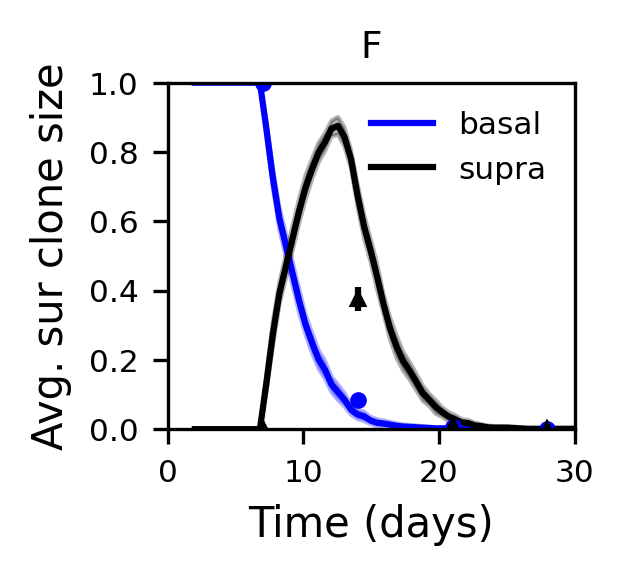

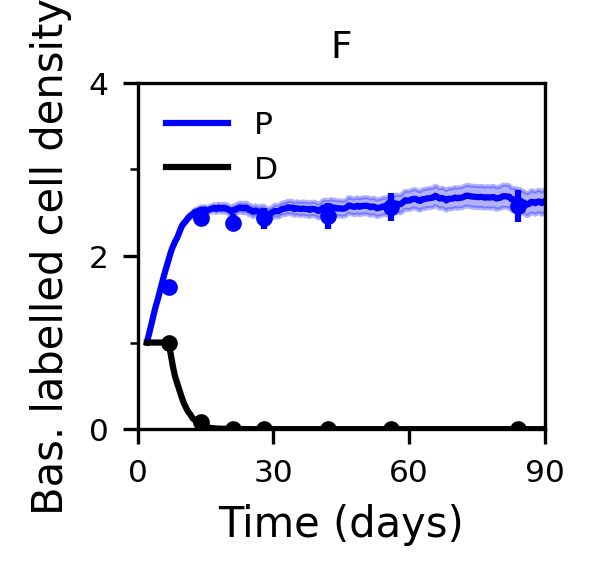

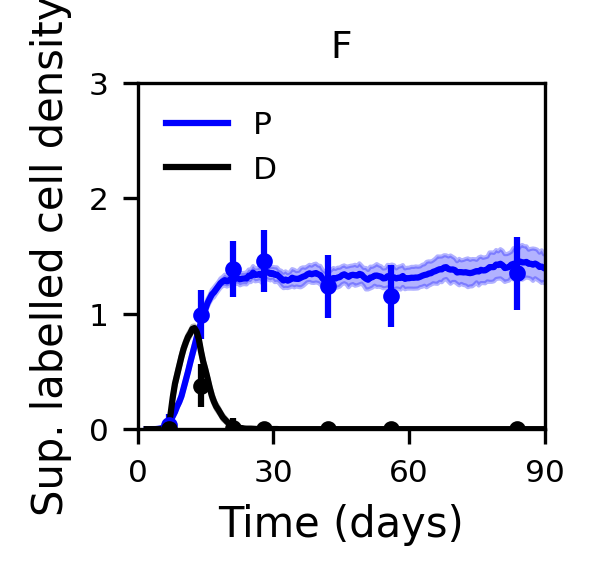

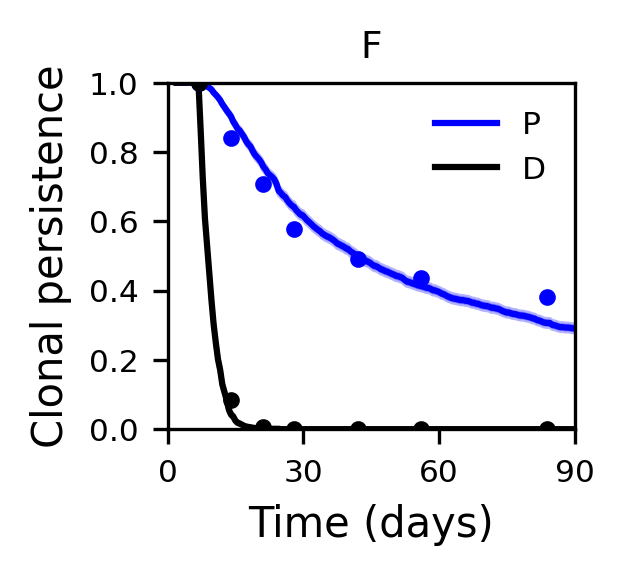








rsync -auv math:/store/BIOPHYS/jth42/glassy-tissue-turnover/S-T-D-model/0D_gamma//../0D_gamma/ctr_SD0D//hrun_SD_0D_t_25000_n_4000_CVd_D_0.4_CVd_S_0.25_corrDD_0.0_corrSD_0.0_corrSS_0.0_r_0.4_rho_0.6_tau_500.0_seed_0.pkl ./../0D_gamma/ctr_SD0D/ &
rsync -auv math:/store/BIOPHYS/jth42/glassy-tissue-turnover/S-T-D-model/0D_gamma//../0D_gamma/ctr_SD0D//hrun_SD_0D_t_25000_n_4000_CVd_D_0.4_CVd_S_0.55_corrDD_0.0_corrSD_0.0_corrSS_0.0_r_0.3_rho_0.4_tau_500.0_seed_0.pkl ./../0D_gamma/ctr_SD0D/ &


In [ ]:
''' 
    t = 25000, n = 4000
'''

ncores = 1

dataset = ['data_ctr_M.pkl',    'data_ctr_F.pkl', 
                'data_castre.pkl', 'data_Ovx.pkl', 
                'data_Lgr6_M.pkl', 'data_Lgr6_F.pkl',
                'data_Notch1_M.pkl', 'data_Notch1_F.pkl']

met = 'full'
best_fits = {}
compute_kwargs = {'Dlike': {'containsBasal': False}}
toCalculate = ['Dlike.basalCS', 'Dlike.supraCS', 'S2like.basalCS', 'S2like.supraCS', 
               'basalCS', 'supraCS', 'S2like.lcd', 'Dlike.lcd', 'S2like.pers', 'Dlike.pers',
               'S2like.fulltotalCS', 'Dlike.fulltotalCS', 'S2like.fullsupraCS',
               'Dlike.fullsupraCS']

model = {0: 'SD_0D', 1: 'STD_0D', 2: 'S_0D', 3: 'SPD_0D', 4: 'ST2D_0D'}


sexname = {'M': 'M', 'F': 'F', 'castre': 'cM'}

sexes = {0: 'M', 1: 'F', 2: 'castre'}
cols = {'M': 'r', 'F': 'b', 'castre': 'purple'}

figsavefolder = 'SFig4_SD_model/F4_'

sim_datasets_full = {}
sim_datasets = {}
exp_datasets = {}

for didx in [0, 1]:
    sex = sexes[didx]
    for mode in [0]:
        print('\n\nModel:', model[mode])
        if didx < 2:
            exp_file = '../experiment/homeo/' + dataset[didx]
        elif didx == 2:
            exp_file = '../experiment/castre/' + dataset[didx]
        elif didx == 3:
            exp_file = '../experiment/ovx/' + dataset[didx]    
        elif didx  < 6:
            exp_file = '../experiment/lgr6/' + dataset[didx]    
        elif didx < 8:
            exp_file = '../experiment/notch/' + dataset[didx]    
        else:
            assert(0)
            
        print(ncores, mode, didx)

        #Metrics
        means  = {'quantity': ['basalCS', 'supraCS'], 'qmetric': 'lLLnb', 'name': 'means', 'exclude_times': {'basalCS': [0,1,2], 'supraCS': [0,1,2]}}
        dists  = {'dist': ['basalCS', 'supraCS'], 'dist_metric': 'lLL', 'name': 'dists', 'exclude_times': {'basalCS': [0,1,2], 'supraCS': [0,1,2]}}
        ksdists  = {'dist': ['S2like.basalCS', 'S2like.supraCS'], 'dist_metric': 'ksd', 'name': 'ksd_b_sb'}
        k1dists  = {'dist': ['S2like.basalCS'], 'dist_metric': 'ksd', 'name': 'ksd_bas'}
        joints = {'custom_metrics': {'jointCS': cmet.logLL_joint}, 'name': 'joint'}
        full = {'custom_metrics': {'S2like.fulljointCS': cmet.logLL_joint, 'Dlike.fulljointCS': cmet.logLL_joint}, 'name': 'full', 
                'exclude_times': {'S2like.fulljointCS': np.arange(6,7)}}

        inc_only_1_2 = np.array([0] + list(np.arange(3,8)))

        lsq_STD = {'quantity': ['S4like.basalCS', 'S4like.supraCS', 'S4like.lcd', 'S4like.pers',
                                    'T3like.basalCS', 'T3like.supraCS', 'T3like.lcd', 'T3like.pers',
                                    'Tlike.basalCS', 'Tlike.supraCS', 'Tlike.lcd', 'Tlike.pers',
                                    'Dlike.basalCS', 'Dlike.supraCS', 'Dlike.lcd', 'Dlike.pers'],
                'qmetric': 'els', 'name': 'STD_lsq',
                'exclude_times': {'T3like.basalCS': np.arange(3,8), 'T3like.supraCS': np.arange(2,8), 'T3like.lcd': np.arange(3,8), 'T3like.pers': inc_only_1_2,
                                'Tlike.basalCS': np.arange(3,8), 'Tlike.supraCS': np.arange(2,8), 'Tlike.lcd': np.arange(3,8), 'Tlike.pers': inc_only_1_2,
                                'Dlike.basalCS': inc_only_1_2, 'Dlike.supraCS': inc_only_1_2, 'Dlike.lcd': inc_only_1_2, 'Dlike.pers': inc_only_1_2,
                                'S4like.pers': np.arange(1)}}
        lll_STD = {'quantity': ['S4like.basalCS', 'S4like.supraCS', 'S4like.lcd', 'S4like.pers',
                                    'T3like.basalCS', 'T3like.supraCS', 'T3like.lcd', 'T3like.pers',
                                    'Tlike.basalCS', 'Tlike.supraCS', 'Tlike.lcd', 'Tlike.pers',
                                    'Dlike.basalCS', 'Dlike.supraCS', 'Dlike.lcd', 'Dlike.pers'],
                'qmetric': 'els', 'name': 'STD_ll',
                'exclude_times': {'T3like.basalCS': np.arange(3,8), 'T3like.supraCS': np.arange(2,8), 'T3like.lcd': np.arange(3,8), 'T3like.pers': inc_only_1_2,
                                'Tlike.basalCS': np.arange(3,8), 'Tlike.supraCS': np.arange(2,8), 'Tlike.lcd': np.arange(3,8), 'Tlike.pers': inc_only_1_2,
                                'Dlike.basalCS': inc_only_1_2, 'Dlike.supraCS': inc_only_1_2, 'Dlike.lcd': inc_only_1_2, 'Dlike.pers': inc_only_1_2,
                                'S4like.pers': np.arange(1)}}

        Dlo = {'custom_metrics': {'Dlike.fulljointCS': cmet.logLL_joint}, 'name': 'Dlo'}
        trans  = {'custom_metrics': {'btranCS': cmet.logLL_move_bas, 'tranCS': cmet.logLL_move_sb}, 'name': 'trans'}
        xf = {'dist': ['S2like.xfrac'], 'dist_metric': 'lLL', 'name': 'xf'}
        #mets = [lsq_STD, lll_STD, full, means, dists, ksdists, k1dists, joints, Dlo, xf]
        mets = [lsq_STD, ksdists, joints, full, means, xf]

        compute_kwargs = {'Dlike': {'containsBasal': False}}


        #Set-up optimiser
        if mode == 0:
            savefolder = '../0D_gamma/ctr_SD0D/'
            s0 = topt.optimizer(sim_model.SD_0D, {'r':   np.arange(0.1, 1.01, 0.05), 
                                                'rho': [0.4, 0.6],
                                                'CVd_S': np.arange(0.1, 1.01, 0.15),
                                                'CVd_D': np.arange(0.1, 1.01, 0.15)},
                                params = {'tau': 500.0, 'corrSD': 0.0, 'corrSS': 0.0, 
                                        'corrSD': 0.0, 'corrDD': 0.0}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate)
            
    
        s0.load_existing(tsteps = 25000, ncells = 4000, savefolder = savefolder, 
                        tscalevals = -np.arange(2,15,0.05), shedvals = -np.arange(0.2, 2.0, 0.1), 
                        postopt_params = {'sbas_cv': np.arange(0.1, 1.01, 0.1)})
        #print(s0.searchspace['rho'].unique())
        if didx == 0:
            s0.searchspace = s0.searchspace[s0.searchspace['rho'] == 0.6]
        elif didx == 1:
            s0.searchspace = s0.searchspace[s0.searchspace['rho'] == 0.4]
        elif didx == 2:
            s0.searchspace = s0.searchspace[s0.searchspace['rho'] == 0.5]
        s0.searchspace = s0.searchspace.reset_index(drop = True)
        
        for met in ['ksd_b_sb']:

            print(dataset[didx], s0.searchspace[met].min(), met)
            #print(s0.boot_stats(met).to_string(float_format=lambda x: f"{x:.3f}"))
            #print(s0.boot_stats(met).to_markdown()) 

            best_fits[(savefolder, dataset[didx], met)] = s0.best_fit(met)
            
            if s0.searchspace[met].min() >= 1e10:
                print('Missing fit')
                continue
            #print(best_fits[(savefolder, dataset[didx])])
            print(s0.sim_save_name(25000, 4000, int(best_fits[(savefolder, dataset[didx], met)].name), 0))
            
            if sex == 'F':
                s0.addparams({'corrSD': 1.0})
            #continue
            sim_data = s0.get_best_fit(met, 25000, 4000, savefolder = savefolder, 
                                       nseeds = 1, save_results = True, skip = 50, 
                                       print_fit = False, init_params = {'relaxsteps': 0, 
                                                                         'homeosteps': 5000},
                                                                         norun = False)
            
            exp_data = s0.exp_data

            sim_datasets_full[sex] = sim_data
            sdt = sim_data.data_time_crop()
            sim_datasets[sex] = sdt
            exp_datasets[sex] = exp_data

            sdt = sim_data.data_time_crop()
            figsavefolder = 'SFig4_SD_model/F4_'
            axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, 
                        xlabel= 'Suprabasal clone size', prelabel= f'{sexname[sex]} sup', bootSEs=True, color = f'{cols[sex]}', 
                            ncols=8, im_width = 1.0, ymax = 1.0, xmax = [10, 10, 10, 10,10,10,10,10],
                            ylabel = 'Frequency', nolegend = False, yscale = 1.5, num_xticks = 3, nogaps = True, 
                            yticks = [0,0.5,1.0])
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_supra_pdf.pdf', dpi = 300)

            axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, xlabel= 'Basal clone size', prelabel= f'{sexname[sex]} bas', bootSEs=True, color = f'{cols[sex]}',
                            ncols=8, im_width = 1.0, ymax = 0.6, xmax = [10, 10, 20, 20,20,20,20,20],
                            ylabel = 'Frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True,
                            yticks = [0, 0.3, 0.6])
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_basal_pdf.pdf', dpi = 300)

            axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                        xlabel= 'Suprabasal clone size', prelabel= f'{sexname[sex]} sup', bootSEs=True, color = f'{cols[sex]}', 
                            ncols=4, im_width = 1.0, ymax = 1.0, xmax = [10,10,10,10],
                            ylabel = 'Frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True, 
                            yticks = [0,0.5,1.0])
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_supra_pdf_short.pdf', dpi = 300)

            axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                                xlabel= 'Basal clone size', prelabel= f'{sexname[sex]} bas', bootSEs=True, color = f'{cols[sex]}',
                            ncols=4, im_width = 1.0, ymax = 0.8, xmax = [10,10,10,10],
                            ylabel = 'Frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True,
                            yticks = [0, 0.4, 0.8])
            #plt.tight_layout()                
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_basal_pdf_short.pdf', dpi = 300)                

            

            plt.figure(figsize = (1.75,1.5), dpi = 300)  
            ds.plot_quantity('S2like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('S2like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Average clone size', plot_seeded = False, bootSEs = True, prelabel = 'supra', color = 'k', xfmt = '^', sfmt = '-')
            plt.xlim([0,90])
            plt.ylim([0,10])
            plt.yticks(np.arange(0, 11, 1),minor = True)
            plt.yticks([0,5,10])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title('Full fits ' + sex + ': P-like')
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_av_size_P.pdf', dpi = 300)
            plt.show() 


            plt.figure(figsize = (1.75,1.5), dpi = 300)  
            ds.plot_quantity('Dlike.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                           ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('Dlike.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'supra', color = 'k', xfmt = '^', sfmt = '-')
            plt.xlim([0,30])
            plt.ylim([0,1])
            plt.xticks(np.arange(0, 31, 10))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_av_size_D.pdf', dpi = 300)
            plt.show()             



            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S2like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'P', color = cols[sex])
            ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Bas. labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(dataset[didx])
            plt.xlim([0,30])
            plt.ylim([0,4])
            plt.yticks(np.arange(0, 4, 1),minor = True)
            plt.yticks([0,2,4])            
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False, loc = 'upper left')
            plt.title(sex)
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_basal_lcd.pdf', dpi = 300)
            plt.show() 

            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S2like.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'P', color = cols[sex])
            ds.plot_quantity('Dlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Sup. labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(dataset[didx])
            plt.xlim([0,30])
            plt.ylim([0,3])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False, loc = 'upper left')
            plt.title(sex)
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_supra_lcd.pdf', dpi = 300)
            plt.show()             

            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S2like.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'P', color = cols[sex])
            ds.plot_quantity('Dlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Clonal persistence', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(dataset[didx])
            plt.xlim([0,90])
            plt.ylim([0,1])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_persistence.pdf', dpi = 300)
            plt.show() 

            print('\n\n')
            
            continue
        
    
print('\n\n\n')


Already cropped
Already cropped
Already cropped
Already cropped


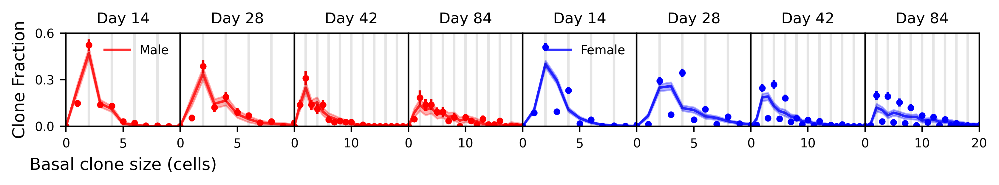

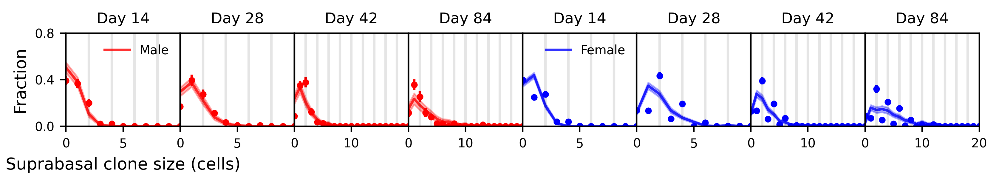

In [ ]:
''' 
    Plot dists alone
'''

fullsex = {'M': 'Male', 'F': 'Female', 'castre': 'Castrated male'}
figfolder = figsavefolder

sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10, 10, 20, 20],
                ylabel = 'Clone Fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2))    

sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]
axs = ds.plot_dist('basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                   xlabel= 'Basal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10, 10, 20, 20],
                ylabel = 'Fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 21, 2), subplot_axs = axs, x0 = 4)  
axs[0].legend(loc='upper right', frameon=False)
axs[4].legend(loc='upper right', frameon=False)
plt.savefig(f'Figures/{figfolder}basal_pdf_short.pdf', dpi = 300)     




sex = 'M'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('S4like.supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, 
                   cdf = False, xlabel= 'Suprabasal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.8, xmax = [10,10,20,20],
                    ylabel = 'Fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                     yticks = [0, 0.4, 0.8], add_vlines = np.arange(0, 30, 2))  
sex = 'F'
exp_data = exp_datasets[sex]
sim_data = sim_datasets_full[sex]
sdt = sim_datasets[sex]

axs = ds.plot_dist('S4like.supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, 
                   cdf = False, xlabel= 'Suprabasal clone size (cells)', prelabel= f'{fullsex[sex]}', 
                    bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.8, xmax = [10,10,20,20],
                    ylabel = 'Fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.4, 0.8], add_vlines = np.arange(0, 30, 2), subplot_axs = axs, x0 = 4)  
axs[0].legend(loc='upper right', frameon=False)
axs[4].legend(loc='upper right', frameon=False)
plt.savefig(f'Figures/{figfolder}supra_pdf_short.pdf', dpi = 300)   



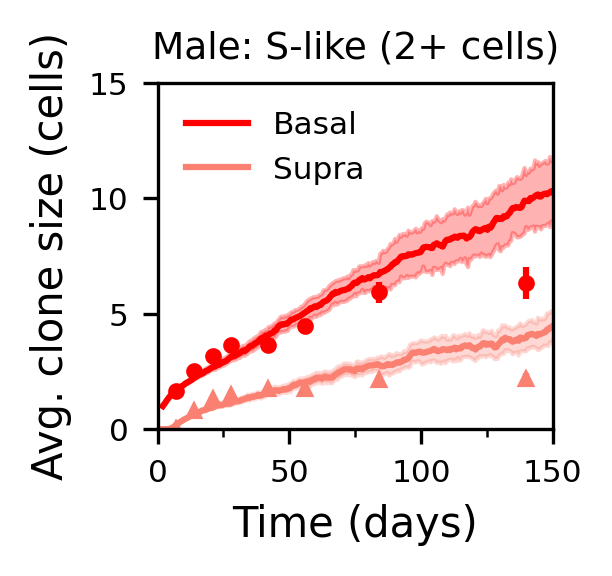

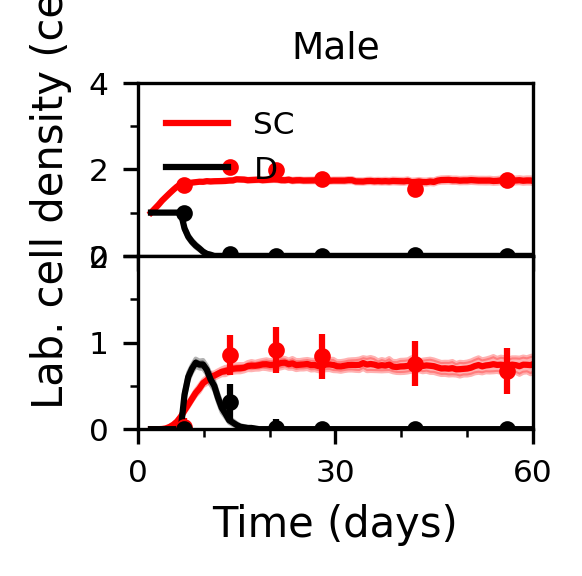

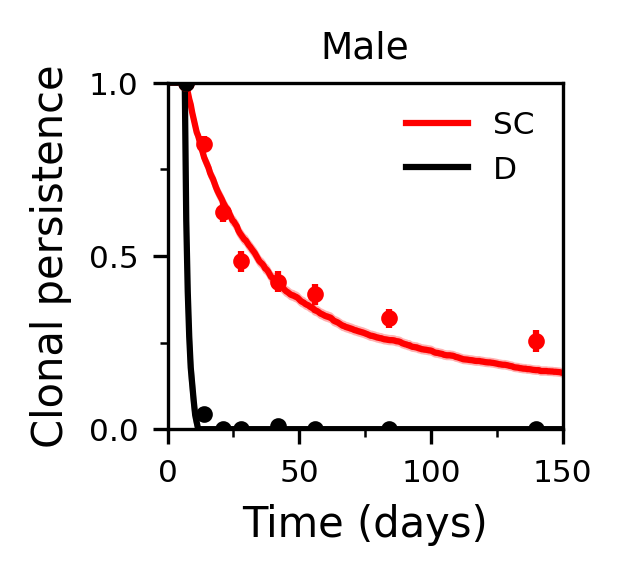

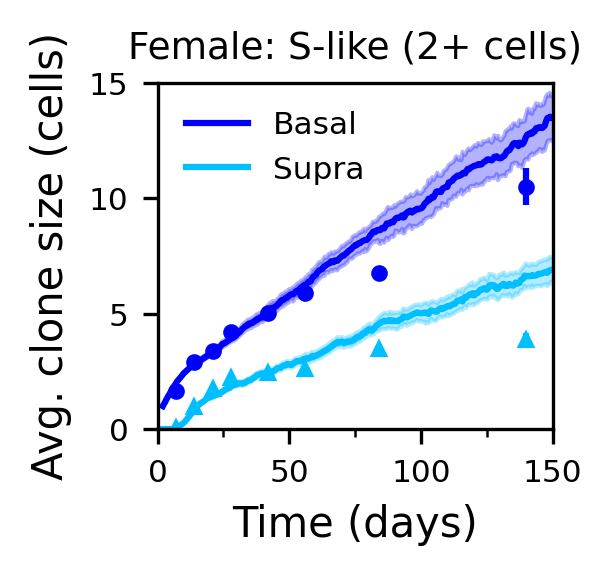

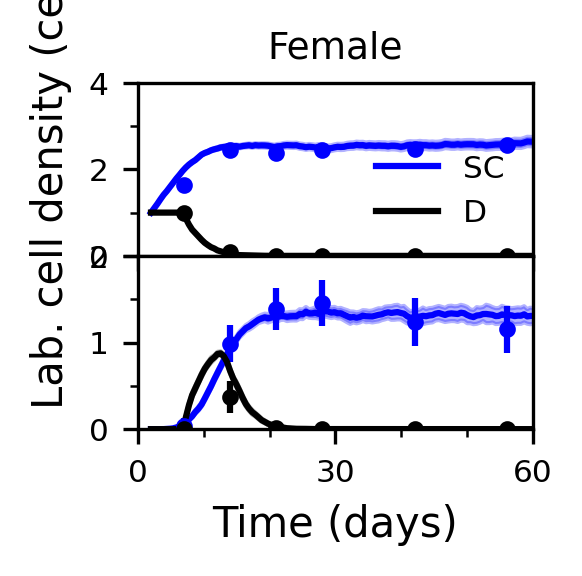

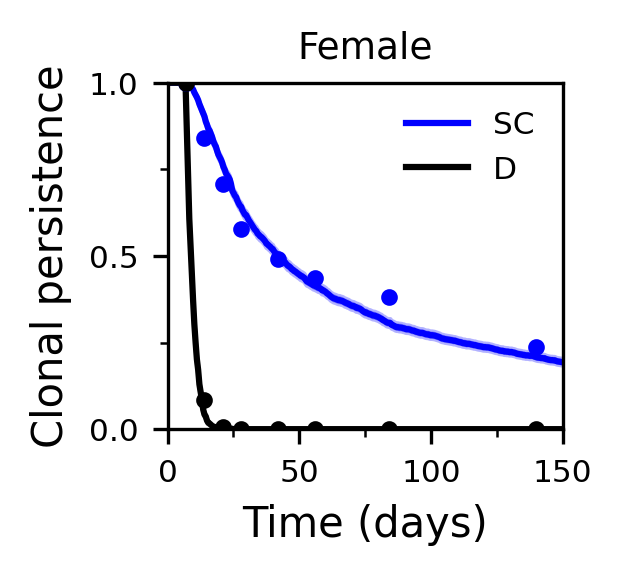

In [ ]:
''' 
    Plot averages for EDFig 3
'''

fullsex = {'M': 'Male', 'F': 'Female', 'castre': 'Castrated male'}
sexname = {'M': 'M', 'F': 'F', 'castre': 'cM'}


for sex in  ['M','F']:
    exp_data = exp_datasets[sex]
    sim_data = sim_datasets_full[sex]
    sdt = sim_datasets[sex]

    sec_cols = {'M': 'salmon', 'F': 'deepskyblue', 'castre': 'violet'}


    plt.figure(figsize = (1.7,1.5), dpi = 300)  
    ds.plot_quantity('S2like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'Basal', color = cols[sex], xfmt = 'o', sfmt = '-')
    ds.plot_quantity('S2like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Avg. clone size (cells)', plot_seeded = False, bootSEs = True, prelabel = 'Supra', color = sec_cols[sex], xfmt = '^', sfmt = '-')
    plt.xlim([0,150])
    plt.ylim([0,15])
    plt.yticks(np.arange(0, 16, 5))
    #plt.yticks(np.arange(0, 13, 2), minor = True)
    plt.xticks(np.arange(0, 151, 50))
    plt.xticks(np.arange(0, 151, 25), minor = True)
    plt.legend(frameon = False)
    plt.title(fullsex[sex] + ': S-like (2+ cells)')
    plt.savefig(f'Figures/{figfolder}{sexname[sex]}_av_size_S2.pdf', dpi = 300)
    plt.show() 


    plt.figure(figsize = (1.7,1.5), dpi = 300)
    plt.subplot(2,1,1)
    ds.plot_quantity('S2like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex])

    #ds.plot_quantity('CPlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
    #                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex])           
    ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Lab. cell density (cells)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
    plt.ylim([0,4])
    plt.yticks(np.arange(0, 5, 2))
    plt.yticks(np.arange(0, 5, 1), minor = True)
    plt.legend(frameon = False)
    plt.title(fullsex[sex])
    plt.xlim([0,60])
    plt.xticks([0,60], minor = True)
    plt.xticks([0,60], minor = False, alpha = 0.0)
    #plt.xticks([])
    plt.xlabel('  ')

    #plt.show()
    plt.subplot(2,1,2)
    ds.plot_quantity('S2like.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex], nolegend = True)
    #ds.plot_quantity('CPlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
    #                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = sec_cols[sex], nolegend = True)           
    ds.plot_quantity('Dlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Supra labelled cell density (cells)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k', nolegend = True)    
    plt.ylim([0,2])
    plt.yticks(np.arange(0, 3, 1))
    plt.yticks(np.arange(0, 2.5, 0.5), minor = True)
    plt.xlim([0,60])
    plt.xticks(np.arange(0, 61, 30))
    plt.xticks(np.arange(0, 61, 10), minor = True)
    plt.title('  ')
    plt.ylabel('  ')
    plt.subplots_adjust(wspace=0, hspace=0)
    #plt.tight_layout()

    plt.savefig(f'Figures/{figfolder}{sexname[sex]}_labelled_cell_density.pdf', dpi = 300)
    plt.show()       
          



    plt.figure(figsize = (1.7,1.5), dpi = 300)
    ds.plot_quantity('S2like.pers', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'SC', color =  cols[sex])
    ds.plot_quantity('Dlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                    ylabel = 'Clonal persistence', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
    #plt.title(fullsex[sex])
    plt.xlim([0,150])
    plt.ylim([0,1])
    plt.yticks(np.arange(0, 1.1, 0.5))
    plt.yticks(np.arange(0, 1.1, 0.25), minor = True)
    plt.xticks(np.arange(0, 151, 50))
    plt.xticks(np.arange(0, 151, 25), minor = True)
    plt.legend(frameon = False)
    plt.title(fullsex[sex])
    plt.savefig(f'Figures/{figfolder}{sexname[sex]}_persistence.pdf', dpi = 300)
    plt.show() 

[0, np.float64(7.0), np.float64(14.0), np.float64(21.0), np.float64(28.0), np.float64(42.0), np.float64(56.0), np.float64(84.0), np.float64(140.0)]
[0, np.float64(7.0), np.float64(14.0), np.float64(21.0), np.float64(28.0), np.float64(42.0), np.float64(56.0), np.float64(84.0), np.float64(140.0)]
[  0.   7.  14.  21.  28.  42.  56.  84. 140.]


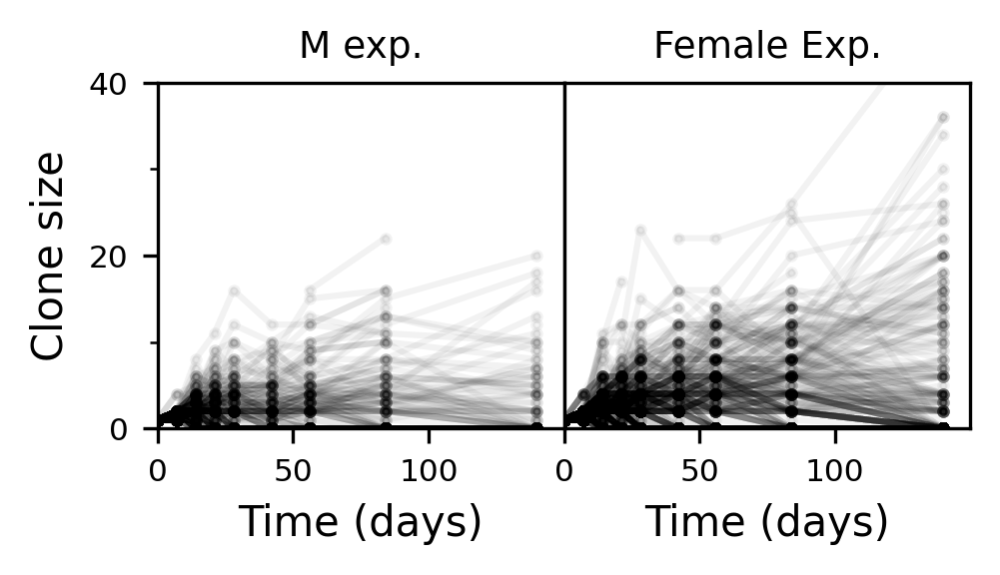

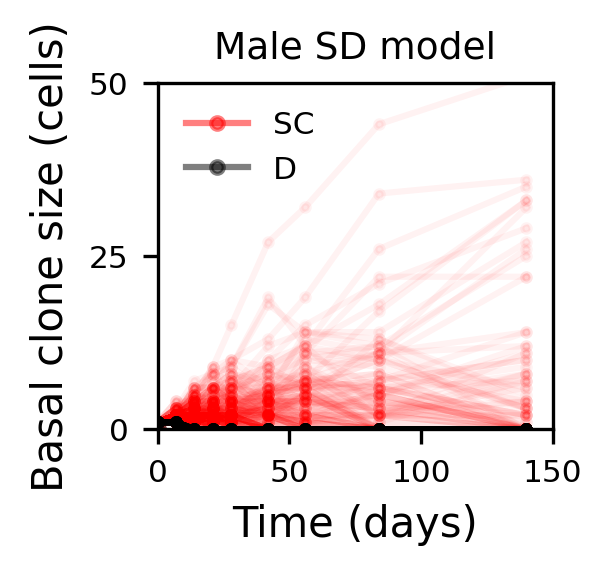

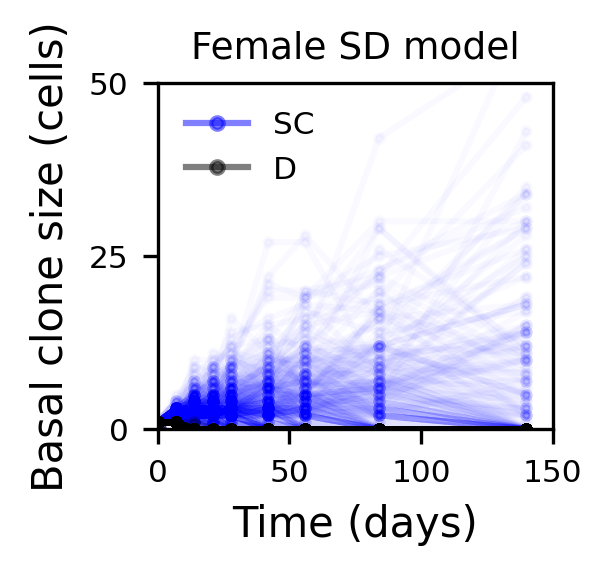

In [47]:
alpha = 0.025

livesize_M = exp_datasets['M'].raw_data['clone_anal'].S2like().live_bas_sb
livesize_F = exp_datasets['F'].raw_data['clone_anal'].S2like().live_bas_sb

livesize_M_D = exp_datasets['M'].raw_data['clone_anal'].Dlike().live_bas_sb
livesize_F_D = exp_datasets['F'].raw_data['clone_anal'].Dlike().live_bas_sb

nDM = livesize_M_D.shape[0]
nDF = livesize_F_D.shape[0]

ls = livesize_M[:,:,0].astype('float')
ls[ls < 0] = np.nan




ls = np.hstack([np.ones((ls.shape[0],1)), ls])
times = [0] + list(exp_datasets['F'].times['basalCS'])
print(times)
nclonesM = ls.shape[0]
plt.figure(figsize=(7,1.5), dpi = 300)
plt.subplot(1,4,1)
plt.plot(times, ls[:,:].T, 'k-o', alpha = 2*alpha, markersize = 2)
plt.title('M')
plt.xlabel('Time (days)')
plt.ylabel('Clone size')
plt.title('M exp.')
plt.ylim([0,40])
plt.yticks([0,20,40])
plt.yticks(np.arange(0, 41, 10), minor = True)
plt.xlim([0,150])
plt.xticks(np.arange(0, 150, 50))

ls = livesize_F[:,:,0].astype('float')
ls[ls < 0] = np.nan
ls = np.hstack([np.ones((ls.shape[0],1)), ls])
times = [0] + list(exp_datasets['F'].times['basalCS'])
nclonesF = ls.shape[0]
print(times)
plt.subplot(1,4,2)
plt.plot(times, ls[:,:].T, 'k-o', alpha = 2*alpha, markersize = 2)
#plt.title('F')
plt.xlabel('Time (days)')
#plt.ylabel('Clone size')
plt.title('Female Exp.')
plt.ylim([0,40])
plt.yticks([])
plt.xlim([0,150])
plt.xticks(np.arange(0, 150, 50))




livesize_M = sim_datasets['M'].raw_data['clone_anal'].S2like().live_bas_sb[:nclonesM,:,:]
livesize_F = sim_datasets['F'].raw_data['clone_anal'].S2like().live_bas_sb[:nclonesF,:,:]

livesize_M_D = sim_datasets['M'].raw_data['clone_anal'].Dlike().live_bas_sb[:nDM,:,:]
livesize_F_D = sim_datasets['F'].raw_data['clone_anal'].Dlike().live_bas_sb[:nDF,:,:]

ls = livesize_M[:,:,0].astype('float')
ls[ls < 0] = np.nan
ls = np.hstack([np.ones((ls.shape[0],1)), ls])

plt.subplots_adjust(wspace=0.0, hspace=0)
times = np.array(times)
plt.figure(figsize = (1.7,1.5), dpi = 300)  
plt.plot(times, -times, 'r-o', alpha = 0.5)
plt.plot(times, -times, 'k-o', alpha = 0.5)
plt.plot(times, ls[:,:].T, 'r-o', alpha = 2*alpha, markersize = 2)
ls = livesize_M_D[:,:,0].astype('float')
ls[ls < 0] = np.nan
ls = np.hstack([np.ones((ls.shape[0],1)), ls])
plt.plot(times, ls[:,:].T, 'k-o', alpha = 2*alpha, markersize = 2)
plt.title('Male SD model')
plt.xlabel('Time (days)')
#plt.ylabel('Clone size')
plt.ylim([0,50])
plt.yticks([0,25,50])
plt.xlim([0,150])
plt.xticks(np.arange(0, 151, 50))
plt.legend(['SC', 'D'], frameon = False)
plt.xlabel('Time (days)')
plt.ylabel('Basal clone size (cells)')
plt.savefig(f'Figures/{figfolder}M_SD_trajectories.pdf', dpi = 300)

ls = livesize_F[:,:,0].astype('float')
ls[ls < 0] = np.nan
ls = np.hstack([np.ones((ls.shape[0],1)), ls])
times = np.array([0] + list(exp_datasets['F'].times['basalCS']))

print(times)
plt.figure(figsize = (1.7,1.5), dpi = 300)  
plt.plot(times, -times, 'b-o', alpha = 0.5)
plt.plot(times, -times, 'k-o', alpha = 0.5)
plt.plot(times, ls[:,:].T, 'b-o', alpha = alpha, markersize = 2)
ls = livesize_F_D[:,:,0].astype('float')
ls[ls < 0] = np.nan
ls = np.hstack([np.ones((ls.shape[0],1)), ls])
plt.plot(times, ls[:,:].T, 'k-o', alpha = alpha, markersize = 2)
plt.title('Female SD model')
plt.xlabel('Time (days)')
plt.legend(['SC', 'D'], frameon = False)
plt.ylim([0,50])
plt.yticks([0,25,50])
plt.xlim([0,150])
plt.xticks(np.arange(0, 151, 50))
plt.xlabel('Time (days)')
plt.ylabel('Basal clone size (cells)')
plt.savefig(f'Figures/{figfolder}F_SD_trajectories.pdf', dpi = 300)

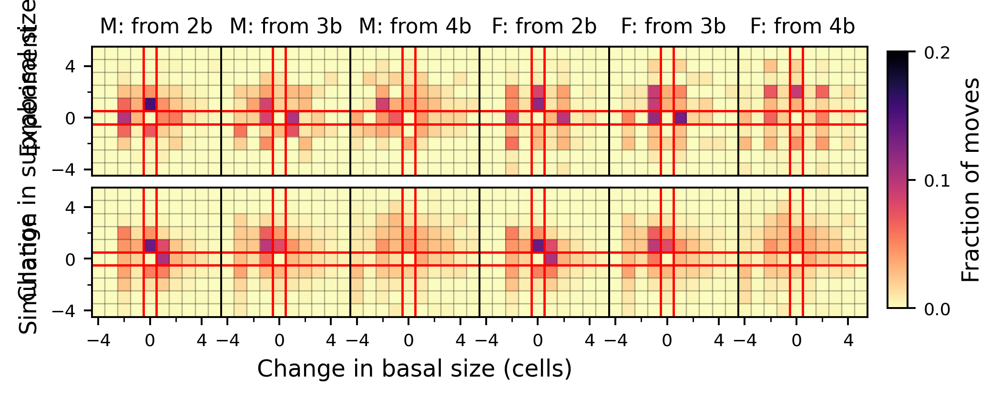

In [46]:
def plot_moves(livesize, init_bas = None, init_sup = None, use_log = False, max_move = 15, normalise = False, 
               tstart = 0, plot = True, tit_prefix = '', vmax = None, cbar = True, labels = True):
    
    if init_bas is None and init_sup is None:
        tit = 'All moves'
    elif init_bas is not None and init_sup is None:
        tit = 'from ' + str(init_bas) + 'b'
    elif init_bas is None and init_sup is not None:
        tit = 'from ' + str(init_sup) + 's'
    elif init_bas is not None and init_sup is not None:
        tit = 'from (' + str(init_bas) + 'b,' + str(init_sup) + 's)'
    
    tit = tit_prefix + tit
    
    moves = livesize[:,tstart+1:,0:2] - livesize[:,tstart:-1,0:2] #lag-1 moves, can also do higher order
    ntimes = moves.shape[1]
    moves[np.abs(moves) > 90] = -max_move

    allmoves = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    for t in range(moves.shape[1]):
        for m in range(moves.shape[0]):
            if init_bas is not None and livesize[m,t+tstart,0] != init_bas:
                continue
                
            if init_sup is not None and livesize[m,t+tstart,1] != init_sup:
                continue
                
            allmoves[t,moves[m,t,0], moves[m,t,1]] += 1
        
    allmoves[:,0,0] = 0
    allmoves[:,-max_move,-max_move] = 0

    np.sum(allmoves,0)
    for mb in range(-9,11):
        for ms in range(-9,11):
            if np.sum(allmoves,0)[mb,ms] > 0:
                #print(mb,ms, allmoves[:,mb,ms])
                continue


    allmoves2 = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    allmoves2[:,:max_move,:max_move] = allmoves[:,-max_move:,-max_move:]
    allmoves2[:,:max_move,-max_move:] = allmoves[:,-max_move:,:max_move]
    allmoves2[:,-max_move:,:max_move] = allmoves[:,:max_move,-max_move:]
    allmoves2[:,-max_move:,-max_move:] = allmoves[:,:max_move,:max_move]
    
    allmoves2[: -max_move,-max_move] = 0

    if normalise:
        allmoves2 = allmoves2/np.sum(allmoves2)
            
    if plot:
        if use_log:
            toplot = np.log2(np.sum(allmoves2,0).T)
        else:
            toplot = np.sum(allmoves2,0).T.astype('float')
            #toplot[toplot == 0.0] = np.nan
        
        plt.imshow(toplot, extent=[-max_move - 0.5,max_move - 0.5,-max_move - 0.5,max_move - 0.5], 
                   origin='lower', cmap = 'magma_r', vmin = 0.0, vmax = vmax) #PuRd#magma_r
        if labels:
            plt.xlabel('Change in basal size (cells)')
            plt.ylabel('Change in suprabasal size (cells)')
        if cbar:
            if use_log:
                plt.colorbar(label = 'log2(# moves)')
            else:
                plt.colorbar(label = 'Fraction of moves')#, ticks = [0, 0.05, 0.1, 0.15])
        plt.vlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.hlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.vlines(np.arange(-0.5,1.,1),-max_move,max_move, color = 'r', linestyles='-', alpha = 1.0, linewidth = 1)
        plt.hlines(np.arange(-0.5,1,1), -max_move,max_move, color = 'r', linestyles='-', alpha = 1.0, linewidth = 1)
        plt.ylim([-max_move,max_move])
        plt.xlim([-max_move,max_move])
        plt.xticks(np.arange(-max_move,max_move+1,4))
        plt.yticks(np.arange(-max_move,max_move+1,4))
        plt.xticks(np.arange(-max_move,max_move+1,2), minor = True)
        plt.yticks(np.arange(-max_move,max_move+1,2), minor = True)        
        plt.title(tit)
        
        if not labels:
            plt.xticks([])
            plt.yticks([])
    
    return allmoves


def make_axis(max_move, i, xlabel_loc = 2, ncols = 3, j = 0, nrows = 1):
    xticks = np.arange(-max_move,max_move+1,2)
    if (i-1) % ncols > 0:
        plt.yticks([])
        plt.yticks([], minor = True)
        plt.ylabel('')
    else:
        plt.yticks(xticks[::2])
        plt.yticks(xticks, minor = True)
    
    if nrows > 1:
        if j > 0:
            plt.ylabel('')

    if j == (nrows - 1):
        if (i - 1) % ncols != xlabel_loc:
            plt.xlabel('')

        xticks = np.arange(-max_move,max_move+1,2)
        plt.xticks(xticks, minor = True) 
        if (i - 1) % ncols < (ncols - 1):
            xticks = xticks[xticks < 8]
        plt.xticks(xticks[::2])  
    else:
        plt.xticks([])
        plt.xlabel('')



sex = 'M'


plt.figure(figsize = (6,2.2), dpi = 350)
max_move = 20
i = 1

j = 0
for sex in ['M', 'F']:
    exp_data = exp_datasets[sex]
    sim_data = sim_datasets[sex]
    i = 1
    for b in [2,3,4]:
        plt.subplot(2,6,i+3*j)
        ax = plt.gca()
        plot_moves(exp_data.raw_data['clone_anal'].live_bas_sb, init_bas = b, init_sup = None, use_log = False, 
                    max_move = max_move, normalise = True, tstart = 0, plot = True, tit_prefix = f'{sex}: ', vmax = 0.2,
                    cbar = False, labels = True)
        
        make_axis(max_move, i+3*j, 2, 6, 0, 2)
        plt.xlim([-4 - 0.5,5.5])
        plt.ylim([-4.5,5.5])
        plt.xticks([])
        plt.xticks([], minor = True)
        plt.xlabel('')
        i += 1  

    i = 1
    for b in [2,3,4]:
        plt.subplot(2,6,6+i+3*j)
        ax = plt.gca()
        plot_moves(sdt.raw_data['clone_anal'].live_bas_sb, init_bas = b, init_sup = None, use_log = False, 
                    max_move = max_move, normalise = True, tstart = 0, plot = True, tit_prefix = f'{sex} ', vmax = 0.2,
                    cbar = False, labels = True)
        
        make_axis(max_move, 6+i+3*j, 2, 6, 1, 2)
        plt.xlim([-4 - 0.5,5.5])
        plt.ylim([-4.5,5.5])
        plt.title('')
        plt.ylabel('')
        i += 1
    j += 1
    
#plt.tight_layout()
plt.subplots_adjust(wspace=0.0, hspace=0)
fig = plt.gcf()
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
mappable = plt.cm.ScalarMappable(cmap='magma_r', norm=plt.Normalize(vmin=0, vmax=0.2))
cbar = fig.colorbar(mappable, cax=cbar_ax, ticks = [0,0.1,0.2])
cbar.set_label('Fraction of moves')

fig.text(0.05, 0.75, 'Experiment', va='center', rotation='vertical', fontsize=10)
fig.text(0.05, 0.25, 'Simulation', va='center', rotation='vertical', fontsize=10)
plt.savefig(f'Figures/{figfolder}_transitions.pdf', dpi = 300)
plt.show()



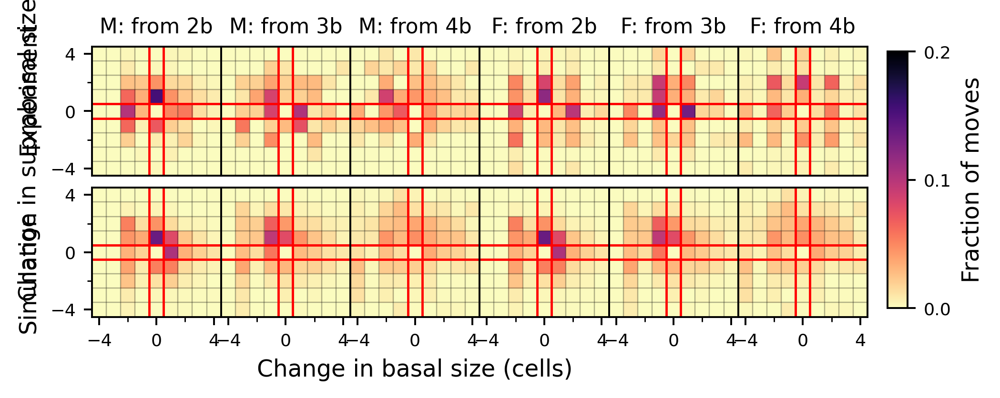

In [30]:


def plot_moves(livesize, init_bas = None, init_sup = None, use_log = False, max_move = 15, normalise = False, 
               tstart = 0, plot = True, tit_prefix = '', vmax = None, cbar = True, labels = True):
    
    if init_bas is None and init_sup is None:
        tit = 'All moves'
    elif init_bas is not None and init_sup is None:
        tit = 'from ' + str(init_bas) + 'b'
    elif init_bas is None and init_sup is not None:
        tit = 'from ' + str(init_sup) + 's'
    elif init_bas is not None and init_sup is not None:
        tit = 'from (' + str(init_bas) + 'b,' + str(init_sup) + 's)'
    
    tit = tit_prefix + tit
    
    moves = livesize[:,tstart+1:,0:2] - livesize[:,tstart:-1,0:2] #lag-1 moves, can also do higher order
    ntimes = moves.shape[1]
    moves[np.abs(moves) > 90] = -max_move

    allmoves = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    for t in range(moves.shape[1]):
        for m in range(moves.shape[0]):
            if init_bas is not None and livesize[m,t+tstart,0] != init_bas:
                continue
                
            if init_sup is not None and livesize[m,t+tstart,1] != init_sup:
                continue
                
            allmoves[t,moves[m,t,0], moves[m,t,1]] += 1
        
    allmoves[:,0,0] = 0
    allmoves[:,-max_move,-max_move] = 0

    np.sum(allmoves,0)
    for mb in range(-9,11):
        for ms in range(-9,11):
            if np.sum(allmoves,0)[mb,ms] > 0:
                #print(mb,ms, allmoves[:,mb,ms])
                continue


    allmoves2 = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    allmoves2[:,:max_move,:max_move] = allmoves[:,-max_move:,-max_move:]
    allmoves2[:,:max_move,-max_move:] = allmoves[:,-max_move:,:max_move]
    allmoves2[:,-max_move:,:max_move] = allmoves[:,:max_move,-max_move:]
    allmoves2[:,-max_move:,-max_move:] = allmoves[:,:max_move,:max_move]
    
    allmoves2[: -max_move,-max_move] = 0

    if normalise:
        allmoves2 = allmoves2/np.sum(allmoves2)
            
    if plot:
        if use_log:
            toplot = np.log2(np.sum(allmoves2,0).T)
        else:
            toplot = np.sum(allmoves2,0).T.astype('float')
            #toplot[toplot == 0.0] = np.nan
        
        plt.imshow(toplot, extent=[-max_move - 0.5,max_move - 0.5,-max_move - 0.5,max_move - 0.5], 
                   origin='lower', cmap = 'magma_r', vmin = 0.0, vmax = vmax) #PuRd#magma_r
        if labels:
            plt.xlabel('Change in basal size (cells)')
            plt.ylabel('Change in suprabasal size (cells)')
        if cbar:
            if use_log:
                plt.colorbar(label = 'log2(# moves)')
            else:
                plt.colorbar(label = 'Fraction of moves')#, ticks = [0, 0.05, 0.1, 0.15])
        plt.vlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.hlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.vlines(np.arange(-0.5,1.,1),-max_move,max_move, color = 'r', linestyles='-', alpha = 1.0, linewidth = 1)
        plt.hlines(np.arange(-0.5,1,1), -max_move,max_move, color = 'r', linestyles='-', alpha = 1.0, linewidth = 1)
        plt.ylim([-max_move,max_move])
        plt.xlim([-max_move,max_move])
        plt.xticks(np.arange(-max_move,max_move+1,4))
        plt.yticks(np.arange(-max_move,max_move+1,4))
        plt.xticks(np.arange(-max_move,max_move+1,2), minor = True)
        plt.yticks(np.arange(-max_move,max_move+1,2), minor = True)        
        plt.title(tit)
        
        if not labels:
            plt.xticks([])
            plt.yticks([])
    
    return allmoves


def make_axis(max_move, i, xlabel_loc = 2, ncols = 3, j = 0, nrows = 1):
    xticks = np.arange(-max_move,max_move+1,2)
    if (i-1) % ncols > 0:
        plt.yticks([])
        plt.yticks([], minor = True)
        plt.ylabel('')
    else:
        plt.yticks(xticks[::2])
        plt.yticks(xticks, minor = True)
    
    if nrows > 1:
        if j > 0:
            plt.ylabel('')

    if j == (nrows - 1):
        if (i - 1) % ncols != xlabel_loc:
            plt.xlabel('')

        xticks = np.arange(-max_move,max_move+1,2)
        plt.xticks(xticks, minor = True) 
        if (i - 1) % ncols < (ncols - 1):
            xticks = xticks[xticks < 8]
        plt.xticks(xticks[::2])  
    else:
        plt.xticks([])
        plt.xlabel('')



sex = 'M'


plt.figure(figsize = (6,2.2), dpi = 350)
max_move = 20
i = 1

j = 0
for sex in ['M', 'F']:
    exp_data = exp_datasets[sex]
    sim_data = sim_datasets[sex]
    i = 1
    for b in [2,3,4]:
        plt.subplot(2,6,i+3*j)
        ax = plt.gca()
        plot_moves(exp_data.raw_data['clone_anal'].live_bas_sb, init_bas = b, init_sup = None, use_log = False, 
                    max_move = max_move, normalise = True, tstart = 0, plot = True, tit_prefix = f'{sex}: ', vmax = 0.2,
                    cbar = False, labels = True)
        
        make_axis(max_move, i+3*j, 2, 6, 0, 2)
        plt.xlim([-4 - 0.5,4.5])
        plt.ylim([-4.5,4.5])
        plt.xticks([])
        plt.xticks([], minor = True)
        plt.xlabel('')
        i += 1  

    i = 1
    for b in [2,3,4]:
        plt.subplot(2,6,6+i+3*j)
        ax = plt.gca()
        plot_moves(sdt.raw_data['clone_anal'].live_bas_sb, init_bas = b, init_sup = None, use_log = False, 
                    max_move = max_move, normalise = True, tstart = 0, plot = True, tit_prefix = f'{sex} ', vmax = 0.2,
                    cbar = False, labels = True)
        
        make_axis(max_move, 6+i+3*j, 2, 6, 1, 2)
        plt.xlim([-4 - 0.5,4.5])
        plt.ylim([-4.5,4.5])
        plt.title('')
        plt.ylabel('')
        i += 1
    j += 1
    
#plt.tight_layout()
plt.subplots_adjust(wspace=0.0, hspace=0)
fig = plt.gcf()
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
mappable = plt.cm.ScalarMappable(cmap='magma_r', norm=plt.Normalize(vmin=0, vmax=0.2))
cbar = fig.colorbar(mappable, cax=cbar_ax, ticks = [0,0.1,0.2])
cbar.set_label('Fraction of moves')

fig.text(0.05, 0.75, 'Experiment', va='center', rotation='vertical', fontsize=10)
fig.text(0.05, 0.25, 'Simulation', va='center', rotation='vertical', fontsize=10)
plt.savefig(f'Figures/{figfolder}_transitions.pdf', dpi = 300)
plt.show()



[0, np.float64(7.0), np.float64(14.0), np.float64(21.0), np.float64(28.0), np.float64(42.0), np.float64(56.0), np.float64(84.0), np.float64(140.0)]
[0, np.float64(7.0), np.float64(14.0), np.float64(21.0), np.float64(28.0), np.float64(42.0), np.float64(56.0), np.float64(84.0), np.float64(140.0)]
[  0.   7.  14.  21.  28.  42.  56.  84. 140.]


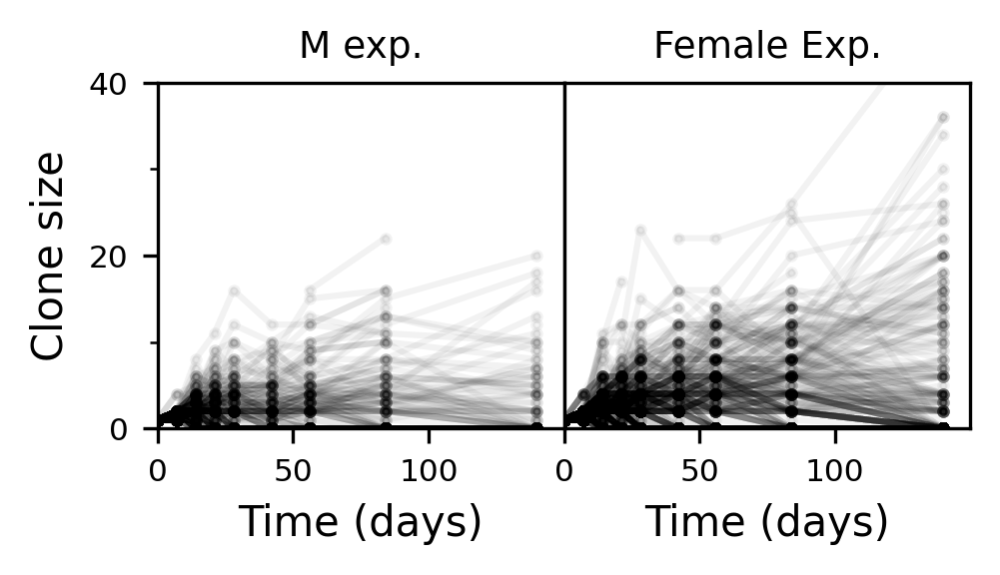

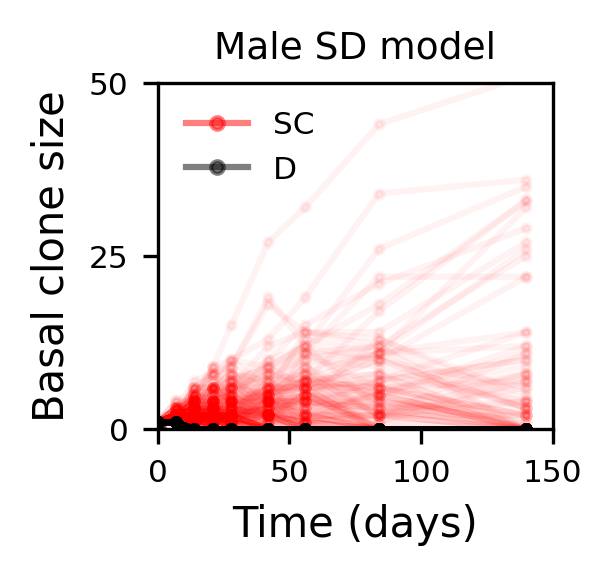

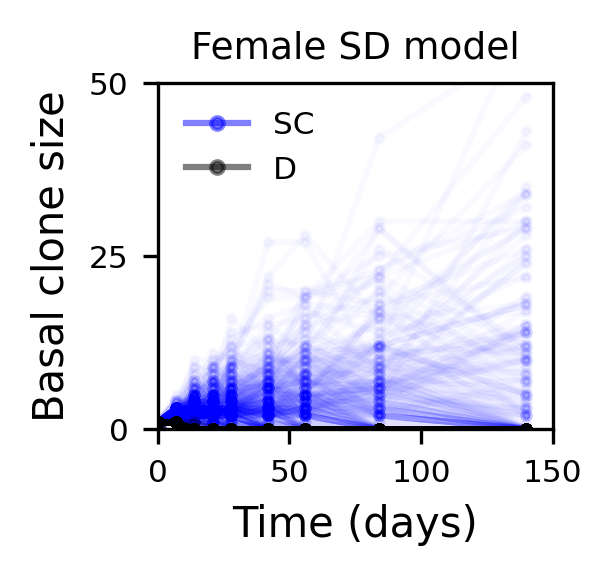

In [ ]:
alpha = 0.025

livesize_M = exp_datasets['M'].raw_data['clone_anal'].S2like().live_bas_sb
livesize_F = exp_datasets['F'].raw_data['clone_anal'].S2like().live_bas_sb

livesize_M_D = exp_datasets['M'].raw_data['clone_anal'].Dlike().live_bas_sb
livesize_F_D = exp_datasets['F'].raw_data['clone_anal'].Dlike().live_bas_sb

nDM = livesize_M_D.shape[0]
nDF = livesize_F_D.shape[0]

ls = livesize_M[:,:,0].astype('float')
ls[ls < 0] = np.nan




ls = np.hstack([np.ones((ls.shape[0],1)), ls])
times = [0] + list(exp_datasets['F'].times['basalCS'])
print(times)
nclonesM = ls.shape[0]
plt.figure(figsize=(7,1.5), dpi = 300)
plt.subplot(1,4,1)
plt.plot(times, ls[:,:].T, 'k-o', alpha = 2*alpha, markersize = 2)
plt.title('M')
plt.xlabel('Time (days)')
plt.ylabel('Clone size')
plt.title('M exp.')
plt.ylim([0,40])
plt.yticks([0,20,40])
plt.yticks(np.arange(0, 41, 10), minor = True)
plt.xlim([0,150])
plt.xticks(np.arange(0, 150, 50))

ls = livesize_F[:,:,0].astype('float')
ls[ls < 0] = np.nan
ls = np.hstack([np.ones((ls.shape[0],1)), ls])
times = [0] + list(exp_datasets['F'].times['basalCS'])
nclonesF = ls.shape[0]
print(times)
plt.subplot(1,4,2)
plt.plot(times, ls[:,:].T, 'k-o', alpha = 2*alpha, markersize = 2)
#plt.title('F')
plt.xlabel('Time (days)')
#plt.ylabel('Clone size')
plt.title('Female Exp.')
plt.ylim([0,40])
plt.yticks([])
plt.xlim([0,150])
plt.xticks(np.arange(0, 150, 50))




livesize_M = sim_datasets['M'].raw_data['clone_anal'].S2like().live_bas_sb[:nclonesM,:,:]
livesize_F = sim_datasets['F'].raw_data['clone_anal'].S2like().live_bas_sb[:nclonesF,:,:]

livesize_M_D = sim_datasets['M'].raw_data['clone_anal'].Dlike().live_bas_sb[:nDM,:,:]
livesize_F_D = sim_datasets['F'].raw_data['clone_anal'].Dlike().live_bas_sb[:nDF,:,:]

ls = livesize_M[:,:,0].astype('float')
ls[ls < 0] = np.nan
ls = np.hstack([np.ones((ls.shape[0],1)), ls])

plt.subplots_adjust(wspace=0.0, hspace=0)
times = np.array(times)
plt.figure(figsize = (1.7,1.5), dpi = 300)  
plt.plot(times, -times, 'r-o', alpha = 0.5)
plt.plot(times, -times, 'k-o', alpha = 0.5)
plt.plot(times, ls[:,:].T, 'r-o', alpha = 2*alpha, markersize = 2)
ls = livesize_M_D[:,:,0].astype('float')
ls[ls < 0] = np.nan
ls = np.hstack([np.ones((ls.shape[0],1)), ls])
plt.plot(times, ls[:,:].T, 'k-o', alpha = 2*alpha, markersize = 2)
plt.title('Male SD model')
plt.xlabel('Time (days)')
#plt.ylabel('Clone size')
plt.ylim([0,50])
plt.yticks([0,25,50])
plt.xlim([0,150])
plt.xticks(np.arange(0, 151, 50))
plt.legend(['SC', 'D'], frameon = False)
plt.xlabel('Time (days)')
plt.ylabel('Basal clone size (cells)')
plt.savefig(f'Figures/{figfolder}M_SD_trajectories.pdf', dpi = 300)

ls = livesize_F[:,:,0].astype('float')
ls[ls < 0] = np.nan
ls = np.hstack([np.ones((ls.shape[0],1)), ls])
times = np.array([0] + list(exp_datasets['F'].times['basalCS']))

print(times)
plt.figure(figsize = (1.7,1.5), dpi = 300)  
plt.plot(times, -times, 'b-o', alpha = 0.5)
plt.plot(times, -times, 'k-o', alpha = 0.5)
plt.plot(times, ls[:,:].T, 'b-o', alpha = alpha, markersize = 2)
ls = livesize_F_D[:,:,0].astype('float')
ls[ls < 0] = np.nan
ls = np.hstack([np.ones((ls.shape[0],1)), ls])
plt.plot(times, ls[:,:].T, 'k-o', alpha = alpha, markersize = 2)
plt.title('Female SD model')
plt.xlabel('Time (days)')
plt.legend(['SC', 'D'], frameon = False)
plt.ylim([0,50])
plt.yticks([0,25,50])
plt.xlim([0,150])
plt.xticks(np.arange(0, 151, 50))
plt.xlabel('Time (days)')
plt.ylabel('Basal clone size (cells)')
plt.savefig(f'Figures/{figfolder}F_SD_trajectories.pdf', dpi = 300)

In [ ]:

means  = {'quantity': ['basalCS', 'supraCS'], 'qmetric': 'lLLnb', 'name': 'means', 'exclude_times': {'basalCS': [0,1,2], 'supraCS': [0,1,2]}}
dists  = {'dist': ['basalCS', 'supraCS'], 'dist_metric': 'lLL', 'name': 'dists', 'exclude_times': {'basalCS': [0,1,2], 'supraCS': [0,1,2]}}
ksdists  = {'dist': ['S2like.basalCS', 'S2like.supraCS'], 'dist_metric': 'ksd', 'name': 'ksd_b_sb'}
k1dists  = {'dist': ['S2like.basalCS'], 'dist_metric': 'ksd', 'name': 'ksd_bas'}
joints = {'custom_metrics': {'jointCS': cmet.logLL_joint}, 'name': 'joint'}
full = {'custom_metrics': {'S2like.fulljointCS': cmet.logLL_joint, 'Dlike.fulljointCS': cmet.logLL_joint}, 'name': 'full', 
        'exclude_times': {'S2like.fulljointCS': np.arange(6,7)}}


ll_dist = {'dist': ['fullbasalCS', 'fullsupraCS', 'S2like.xfrac'], 
                    'dist_metric': 'lLL', 'name': 'll_dist'}

ll_dist_STD = {'dist': ['Slike.fullbasalCS', 'Slike.fullsupraCS',
                    'Tlike.fullbasalCS', 'Tlike.fullsupraCS',
                    'Dlike.fullbasalCS', 'Dlike.fullsupraCS', 
                    'S2like.xfrac'], 
                    'dist_metric': 'lLL', 'name': 'll_STD'}


inc_only_1_2 = np.array([0] + list(np.arange(3,8)))

lsq_STD = {'quantity': ['S4like.basalCS', 'S4like.supraCS', 'S4like.lcd', 'S4like.pers',
                            'T3like.basalCS', 'T3like.supraCS', 'T3like.lcd', 'T3like.pers',
                            'Tlike.basalCS', 'Tlike.supraCS', 'Tlike.lcd', 'Tlike.pers',
                            'Dlike.basalCS', 'Dlike.supraCS', 'Dlike.lcd', 'Dlike.pers'],
        'qmetric': 'els', 'name': 'STD_lsq',
        'exclude_times': {'T3like.basalCS': np.arange(3,8), 'T3like.supraCS': np.arange(2,8), 'T3like.lcd': np.arange(3,8), 'T3like.pers': inc_only_1_2,
                        'Tlike.basalCS': np.arange(3,8), 'Tlike.supraCS': np.arange(2,8), 'Tlike.lcd': np.arange(3,8), 'Tlike.pers': inc_only_1_2,
                        'Dlike.basalCS': inc_only_1_2, 'Dlike.supraCS': inc_only_1_2, 'Dlike.lcd': inc_only_1_2, 'Dlike.pers': inc_only_1_2,
                        'S4like.pers': np.arange(1)}}
lll_STD = {'quantity': ['S4like.basalCS', 'S4like.supraCS', 'S4like.lcd', 'S4like.pers',
                            'T3like.basalCS', 'T3like.supraCS', 'T3like.lcd', 'T3like.pers',
                            'Tlike.basalCS', 'Tlike.supraCS', 'Tlike.lcd', 'Tlike.pers',
                            'Dlike.basalCS', 'Dlike.supraCS', 'Dlike.lcd', 'Dlike.pers'],
        'qmetric': 'els', 'name': 'STD_ll',
        'exclude_times': {'T3like.basalCS': np.arange(3,8), 'T3like.supraCS': np.arange(2,8), 'T3like.lcd': np.arange(3,8), 'T3like.pers': inc_only_1_2,
                        'Tlike.basalCS': np.arange(3,8), 'Tlike.supraCS': np.arange(2,8), 'Tlike.lcd': np.arange(3,8), 'Tlike.pers': inc_only_1_2,
                        'Dlike.basalCS': inc_only_1_2, 'Dlike.supraCS': inc_only_1_2, 'Dlike.lcd': inc_only_1_2, 'Dlike.pers': inc_only_1_2,
                        'S4like.pers': np.arange(1)}}

Dlo = {'custom_metrics': {'Dlike.fulljointCS': cmet.logLL_joint}, 'name': 'Dlo'}
trans  = {'custom_metrics': {'btranCS': cmet.logLL_move_bas, 'tranCS': cmet.logLL_move_sb}, 'name': 'trans'}
xf = {'dist': ['S2like.xfrac'], 'dist_metric': 'lLL', 'name': 'xf'}
mets = [ll_dist_STD, ll_dist, ksdists, k1dists, full, joints, lsq_STD, xf]

compute_kwargs = {'Dlike': {'containsBasal': False}}


ncores = 1

dataset = ['data_ctr_M.pkl',    'data_ctr_F.pkl', 
                'data_castre.pkl', 'data_Ovx.pkl', 
                'data_Lgr6_M.pkl', 'data_Lgr6_F.pkl',
                'data_Notch1_M.pkl', 'data_Notch1_F.pkl']


met = 'full'
best_fits = {}
compute_kwargs = {'Dlike': {'containsBasal': False}}
toCalculate = ['Dlike.basalCS', 'Dlike.supraCS', 'S2like.basalCS', 'S2like.supraCS', 
               'basalCS', 'supraCS', 'S2like.lcd', 'Dlike.lcd', 'S2like.pers', 'Dlike.pers',
               'S2like.fulltotalCS', 'Dlike.fulltotalCS', 'lcd', 'totalCS']

model = {0: 'SD_0D', 1: 'STD_0D', 2: 'S_0D', 3: 'SPD_0D', 4: 'ST2D_0D'}




for didx in [0, 1]:
    sex = sexes[didx]
    for mode in [0]:
        print('\n\nModel:', model[mode])
        if didx < 2:
            exp_file = '../experiment/homeo/' + dataset[didx]
        elif didx == 2:
            exp_file = '../experiment/castre/' + dataset[didx]
        elif didx == 3:
            exp_file = '../experiment/ovx/' + dataset[didx]    
        elif didx  < 6:
            exp_file = '../experiment/lgr6/' + dataset[didx]    
        elif didx < 8:
            exp_file = '../experiment/notch/' + dataset[didx]    
        else:
            assert(0)
        print(ncores, mode, didx)


        #Set-up optimiser
        if mode == 0:
            savefolder = '../0D_gamma/ctr_SD0D/'
            s0 = topt.optimizer(sim_model.SD_0D, {'r':   np.arange(0.1, 0.71, 0.05), 
                                                'rho': [0.4, 0.5, 0.6],
                                                'CVd_S': np.arange(0.45, 1.01, 0.15),
                                                'CVd_D': np.arange(0.1, 1.01, 0.15),
                                                'corrSD': [0.0, 1.0],
                                                'corrSS': [0.0, 0.75]},
                                params = {'tau': 100.0, # 500.0
                                        'corrDD': -1}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate)
            
        
    
        s0.load_existing(tsteps = 7500, ncells = 1000, savefolder = savefolder, 
                        tscalevals = -np.arange(2,15,0.05), shedvals = -np.arange(0.2, 2.0, 0.1), 
                        postopt_params = {'sbas_cv': np.arange(0.1, 1.01, 0.1)})
        
        if didx == 0:
            s0.searchspace = s0.searchspace[(s0.searchspace['rho'] == 0.6)]
        elif didx == 1:
            s0.searchspace = s0.searchspace[s0.searchspace['rho'] == 0.4]
        elif didx == 2:
            s0.searchspace = s0.searchspace[s0.searchspace['rho'] == 0.5]            
        s0.searchspace = s0.searchspace.reset_index(drop = True)
        
        for met in ['full']:

            print(dataset[didx], s0.searchspace[met].min(), met)
            print(s0.boot_stats(met).to_string(float_format=lambda x: f"{x:.3f}"))
            print(s0.boot_stats(met).to_markdown())            

            best_fits[(savefolder, dataset[didx], met)] = s0.best_fit(met)
            
            if s0.searchspace[met].min() >= 1e10:
                print('Missing fit')
                continue
            #print(best_fits[(savefolder, dataset[didx])])
            print(s0.sim_save_name(7500, 1000, int(best_fits[(savefolder, dataset[didx], met)].name), 0))

            continue
            sim_data = s0.get_best_fit(met, 7500, 5000, savefolder = savefolder, nseeds = 1, save_results = True, 
                                       skip = 5, print_fit = False, norun = False)
            exp_data = s0.exp_data

            plt.figure(figsize = (2,2), dpi = 300)  
            ds.plot_quantity('S2like.basalCS', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'Mean clone size', plot_seeded = False, prelabel = 'S bas', color = 'g')
            ds.plot_quantity('S2like.supraCS', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'Mean clone size', plot_seeded = False, prelabel = 'S sup', color = 'b')  
            ds.plot_quantity('Dlike.basalCS', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'Mean clone size', plot_seeded = False, prelabel = 'D bas', color = 'k')
            ds.plot_quantity('Dlike.supraCS', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'Mean clone size', plot_seeded = False, prelabel = 'D sup', color = 'm')      
            #plt.title(dataset[didx] + ', S2like')
            plt.xlim([0,90])
            plt.ylim([0,10])
            plt.xticks([0, 30, 60, 90])
            plt.yticks([0, 5, 10])
            plt.yticks(np.arange(0,10.5,2), minor = True)
            plt.show() 

            plt.figure()
            ds.plot_quantity('S2like.lcd', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'LCD', plot_seeded = False, prelabel = 'S basal')
            ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'LCD', plot_seeded = False, prelabel = 'D basal', color = 'g')
            ds.plot_quantity('S2like.fulltotalCS', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'LCD', plot_seeded = False, prelabel = 'S total', color = 'b')
            ds.plot_quantity('Dlike.fulltotalCS', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'LCD', plot_seeded = False, prelabel = 'D total', color = 'r')            
            plt.title(dataset[didx])
            plt.xlim([0,90])
            plt.ylim([0,5])

            plt.show() 

            plt.figure()
            ds.plot_quantity('S2like.pers', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'Persistence', plot_seeded = False, prelabel = 'S2')
            ds.plot_quantity('Dlike.pers', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'Persistence', plot_seeded = False, prelabel = 'D', color = 'g')    
            plt.title(dataset[didx])
            plt.xlim([0,90])
            plt.ylim([0,1])
            plt.show() 


            sdt = sim_data.data_time_crop()
            #assert(0)

            axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, xlabel= 'clone size', prelabel= 'bas', bootSEs=True)
            axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, xlabel= 'clone size', prelabel= 'sup', bootSEs=True, color = 'g', subplot_axs = axs)
            plt.show()

            axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = True, xlabel= 'clone size', prelabel= 'bas', bootSEs=True)
            axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = True, xlabel= 'clone size', prelabel= 'sup', bootSEs=True, color = 'g', subplot_axs = axs)
            plt.show()   

            print('\n\n')
            
            continue
        
    
print('\n\n\n')




Model: SD_0D
1 0 22
dan_2410_ctr_M.pkl 4092.7494596772553 full
                Best    Mean  Median   Std     Min     Max                                      95% CI                                      68% CI
corrSS         0.000   0.000   0.000 0.000   0.000   0.000                                  [0.0, 0.0]                                  [0.0, 0.0]
corrSD         1.000   1.000   1.000 0.000   1.000   1.000                                  [1.0, 1.0]                                  [1.0, 1.0]
full:shed     -0.600  -0.606  -0.600 0.031  -0.800  -0.600                                [-0.7, -0.6]                                [-0.6, -0.6]
CVd_S          0.450   0.452   0.450 0.015   0.450   0.600                                [0.45, 0.45]                                [0.45, 0.45]
r              0.450   0.453   0.450 0.016   0.450   0.600                 [0.45, 0.47624999999999956]                                [0.45, 0.45]
CVd_D          0.550   0.544   0.550 0.056   0.100   



Model: SD_0D
1 0 22
dan_2410_ctr_M.pkl 1.819133371536065 ksd_b_sb
                    Best    Mean  Median    Std      Min     Max                                      95% CI                                      68% CI
tau              -16.000 -18.076 -16.000  3.931  -50.000 -15.504  [-21.978021978021978, -15.503875968992247]  [-20.833333333333336, -15.503875968992247]
rho                0.600   0.600   0.600  0.000    0.600   0.600                                  [0.6, 0.6]                                  [0.6, 0.6]
corrSS             0.000   0.075   0.000  0.225    0.000   0.750                                 [0.0, 0.75]                                  [0.0, 0.0]
CVd_S              0.450   0.468   0.450  0.061    0.450   0.900                                 [0.45, 0.6]                                [0.45, 0.45]
CVd_D              0.400   0.393   0.400  0.210    0.100   0.700                                  [0.1, 0.7]                                  [0.1, 0.7]
ksd_b_sb:shed 

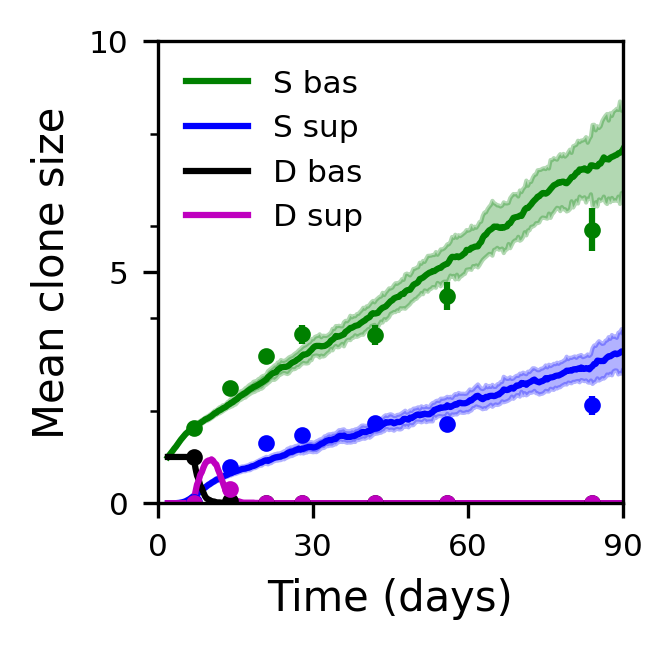

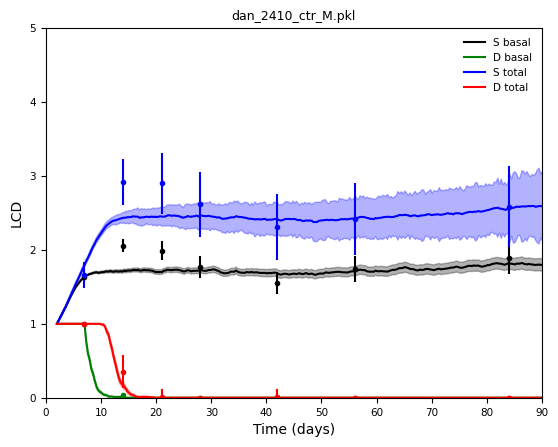

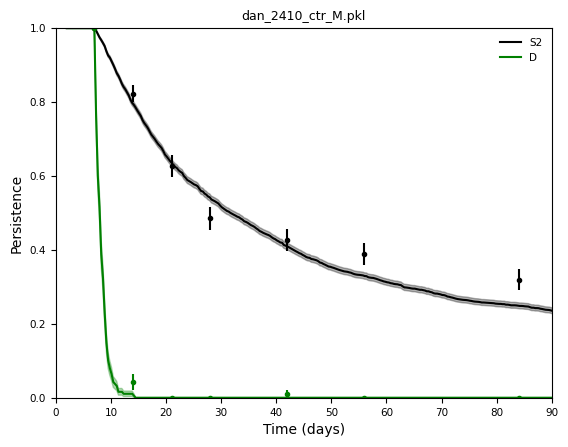

Already cropped
Already cropped


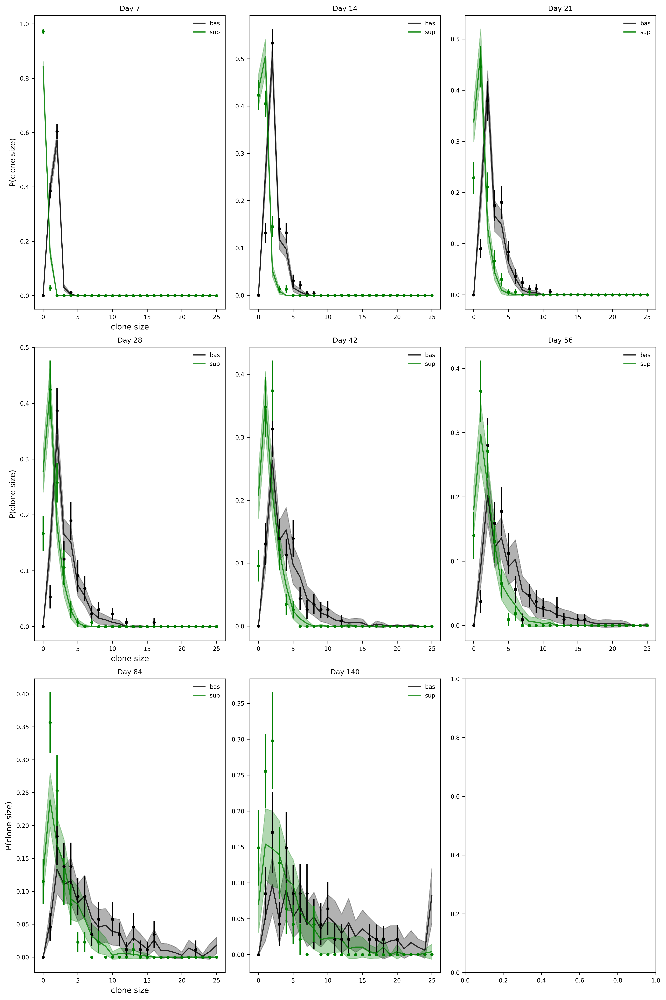

Already cropped
Already cropped


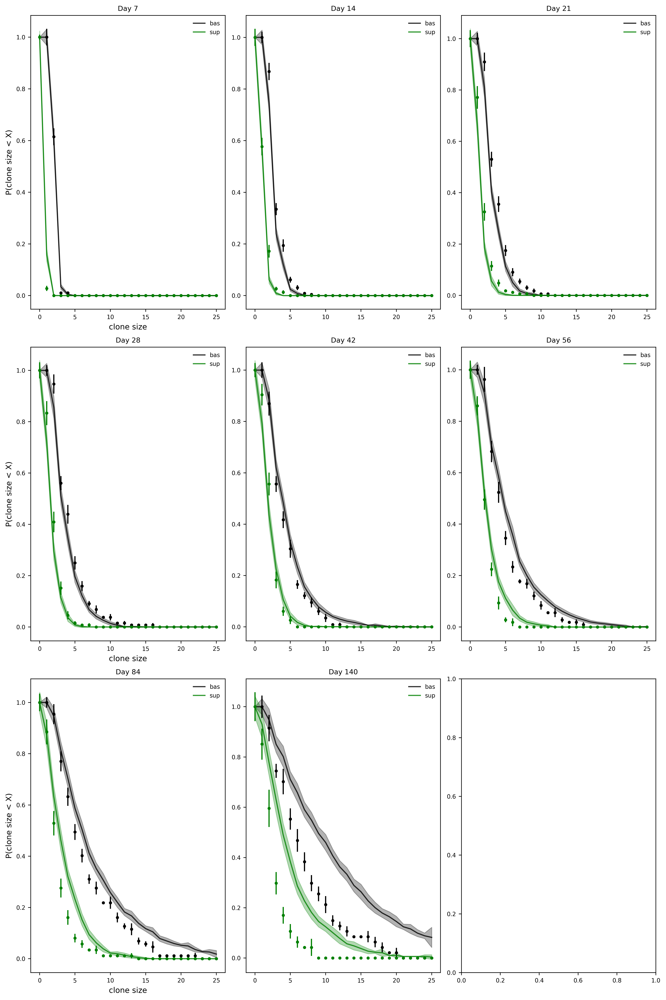






Model: SD_0D
1 0 23
dan_2410_ctr_F.pkl 1.9065462319458244 ksd_b_sb
boot_costshas inconsistent shapes
boot_tscalehas inconsistent shapes
boot_costshas inconsistent shapes
boot_costshas inconsistent shapes
boot_costshas inconsistent shapes
boot_costshas inconsistent shapes
boot_costshas inconsistent shapes
boot_costshas inconsistent shapes
boot_costshas inconsistent shapes
boot_costshas inconsistent shapes
boot_costshas inconsistent shapes
boot_costshas inconsistent shapes
boot_costshas inconsistent shapes
boot_tscalehas inconsistent shapes
boot_costshas inconsistent shapes
boot_costshas inconsistent shapes
boot_costshas inconsistent shapes
                    Best    Mean  Median    Std      Min     Max                                     95% CI                                    68% CI
tau              -21.053 -21.568 -21.053  1.769  -29.851 -21.053   [-28.42844600526778, -21.05263157894737]  [-21.05263157894737, -21.05263157894737]
rho                0.400   0.400   0.400  0.000 

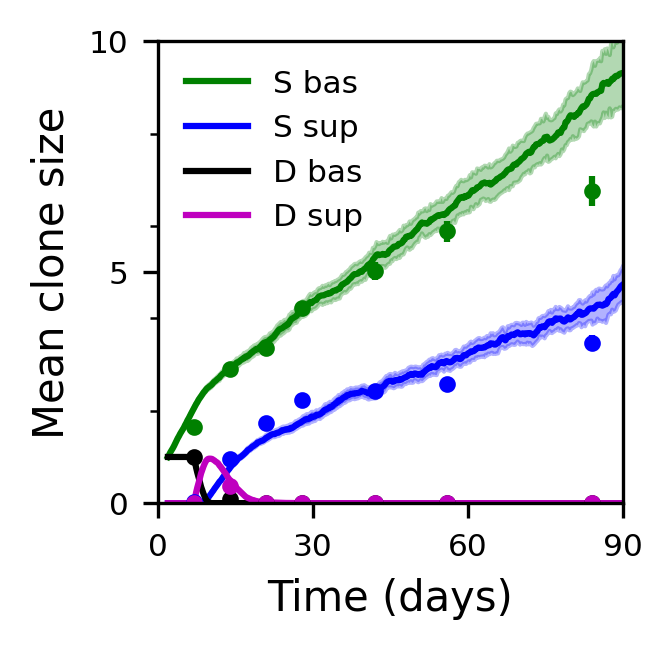

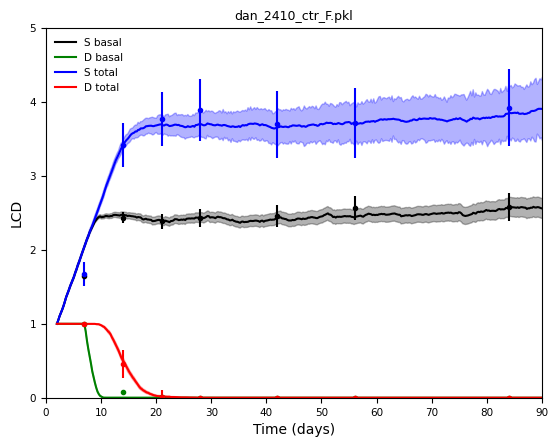

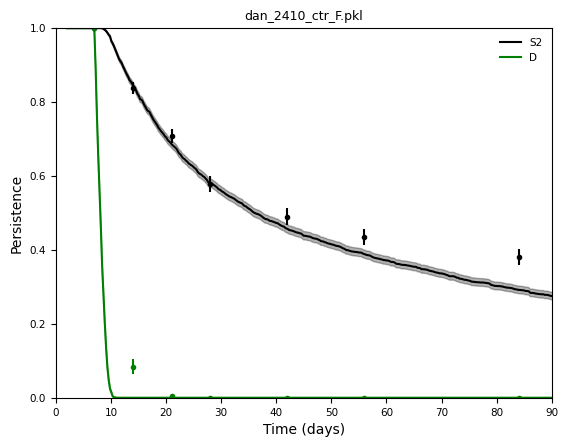

Already cropped
Already cropped


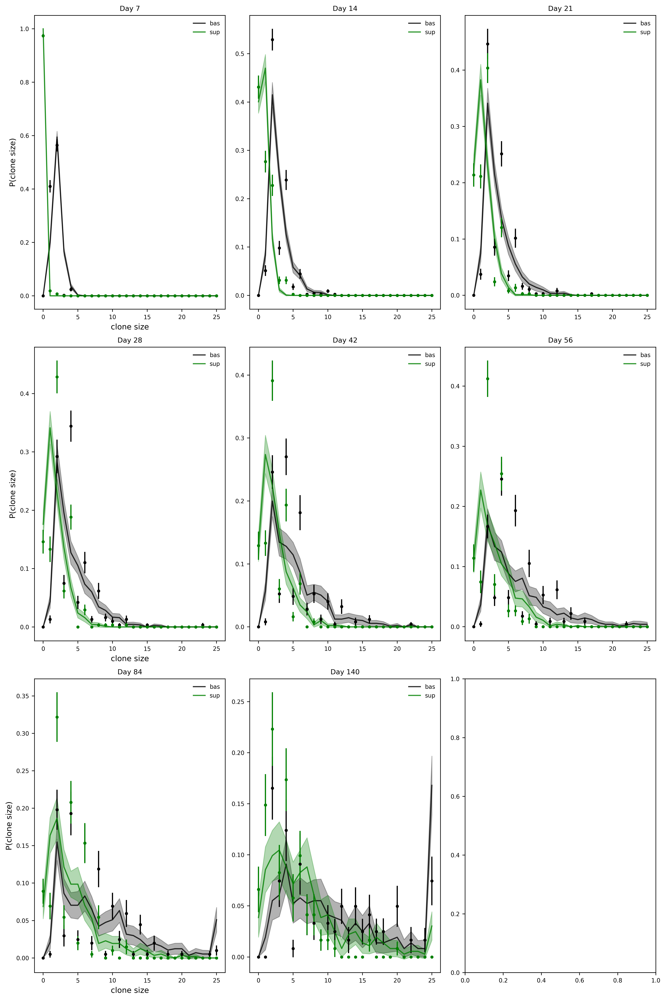

Already cropped
Already cropped


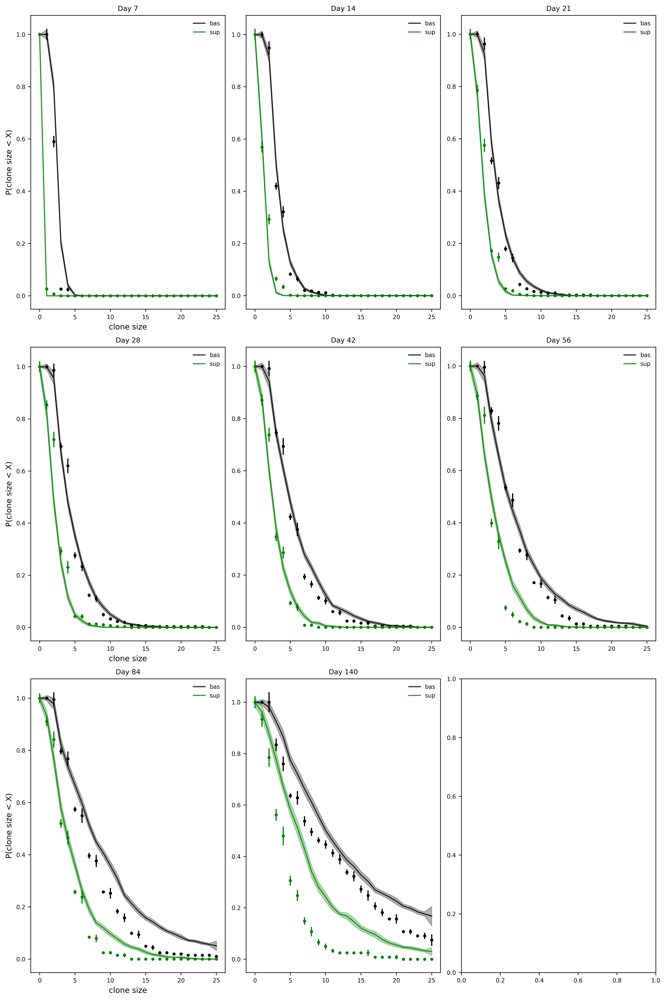






Model: SD_0D
1 0 24
dan_2412_castre.pkl 1.241213258635098 ksd_b_sb
                    Best    Mean  Median   Std     Min     Max                                     95% CI                                     68% CI
tau              -21.739 -21.545 -21.739 1.361 -25.316 -19.048  [-23.80952380952381, -19.047619047619047]  [-22.98850574712644, -19.607843137254903]
rho                0.500   0.500   0.500 0.000   0.500   0.500                                 [0.5, 0.5]                                 [0.5, 0.5]
corrSS             0.000   0.030   0.000 0.147   0.000   0.750                                [0.0, 0.75]                                 [0.0, 0.0]
CVd_S              0.600   0.549   0.600 0.071   0.450   0.600                                [0.45, 0.6]                                [0.45, 0.6]
CVd_D              0.250   0.243   0.250 0.141   0.100   0.700                                 [0.1, 0.7]                                [0.1, 0.25]
ksd_b_sb:shed     -1.000  -1.031  

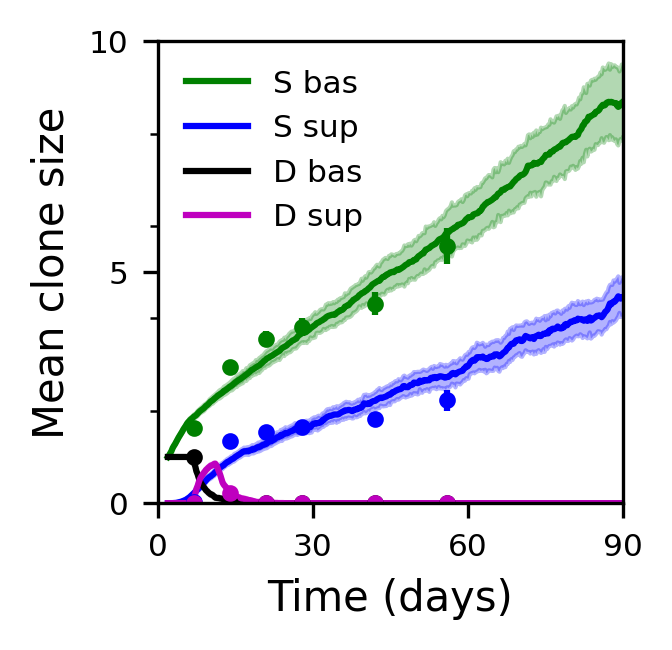

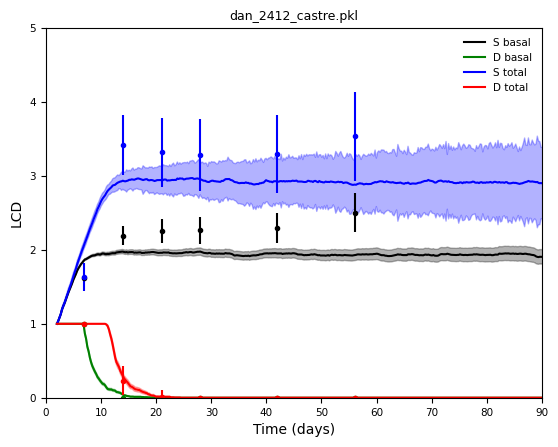

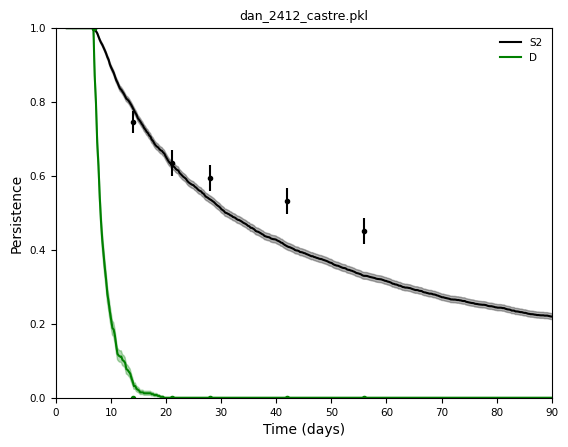

Already cropped
Already cropped


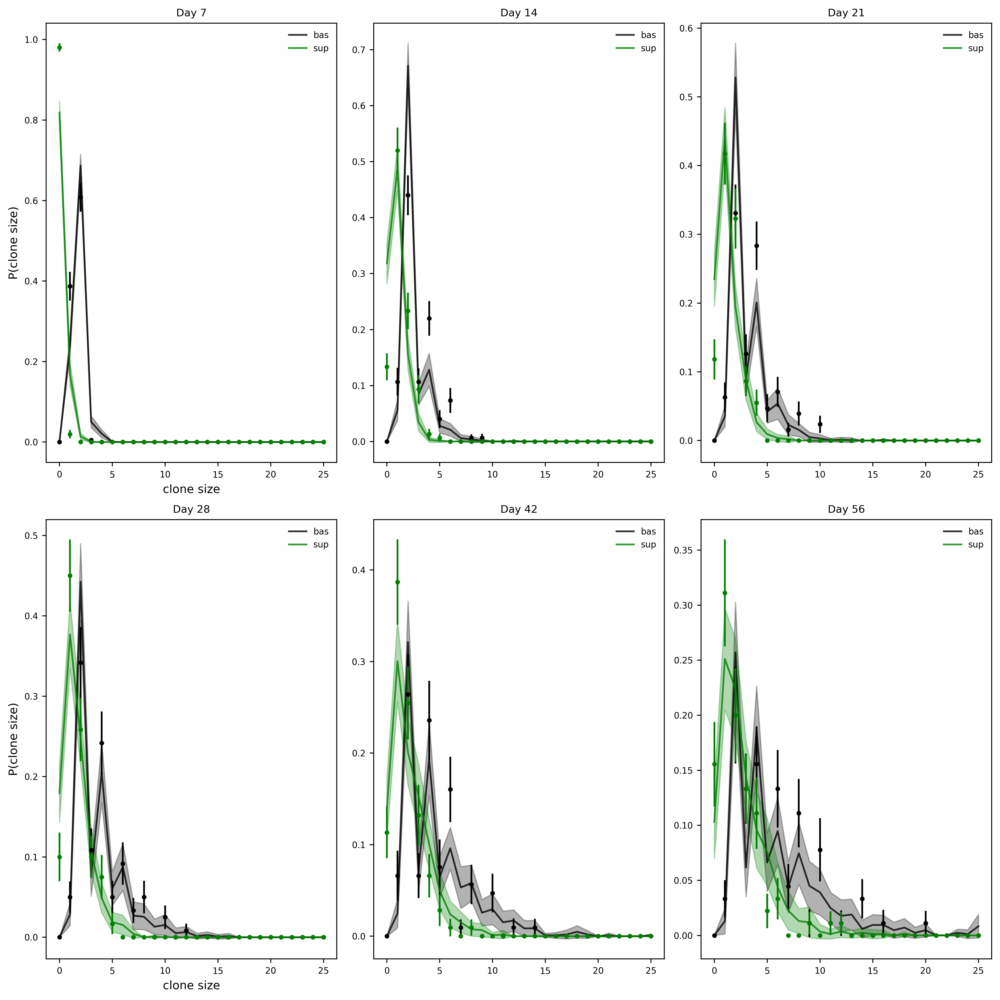

Already cropped
Already cropped


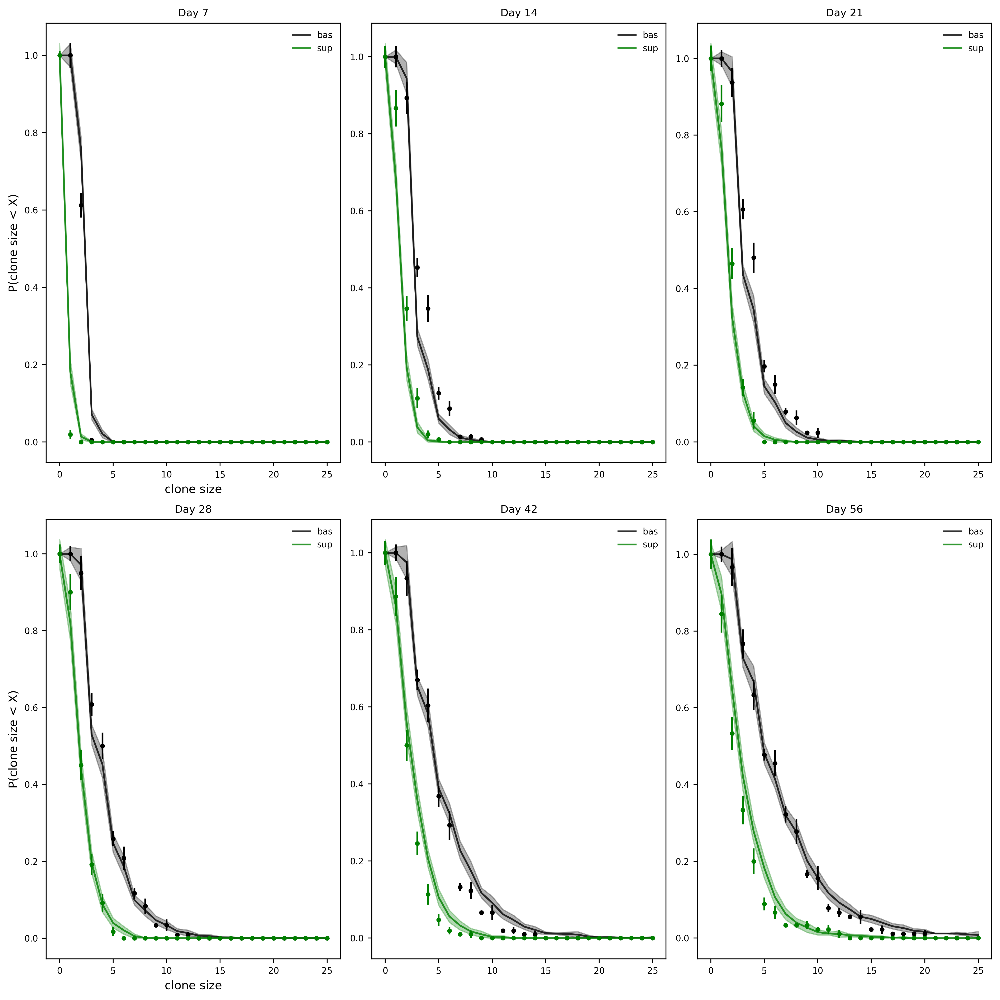








rsync -auv math:/store/BIOPHYS/jth42/glassy-tissue-turnover/S-T-D-model/0D_gamma//../0D_gamma/ctr_SD0D//hrun_SD_0D_t_7500_n_1000_CVd_D_0.4_CVd_S_0.45_corrDD_-1.0_corrSD_1.0_corrSS_0.0_r_0.45_rho_0.6_tau_100.0_seed_0.pkl ./../0D_gamma/ctr_SD0D/ &
rsync -auv math:/store/BIOPHYS/jth42/glassy-tissue-turnover/S-T-D-model/0D_gamma//../0D_gamma/ctr_SD0D//hrun_SD_0D_t_7500_n_1000_CVd_D_0.1_CVd_S_0.6_corrDD_-1.0_corrSD_0.0_corrSS_0.75_r_0.3_rho_0.4_tau_100.0_seed_0.pkl ./../0D_gamma/ctr_SD0D/ &
rsync -auv math:/store/BIOPHYS/jth42/glassy-tissue-turnover/S-T-D-model/0D_gamma//../0D_gamma/ctr_SD0D//hrun_SD_0D_t_7500_n_1000_CVd_D_0.25_CVd_S_0.6_corrDD_-1.0_corrSD_1.0_corrSS_0.0_r_0.35_rho_0.5_tau_100.0_seed_0.pkl ./../0D_gamma/ctr_SD0D/ &


In [ ]:
''' 
    Comparing different metrics
'''


means  = {'quantity': ['basalCS', 'supraCS'], 'qmetric': 'lLLnb', 'name': 'means', 'exclude_times': {'basalCS': [0,1,2], 'supraCS': [0,1,2]}}
dists  = {'dist': ['basalCS', 'supraCS'], 'dist_metric': 'lLL', 'name': 'dists', 'exclude_times': {'basalCS': [0,1,2], 'supraCS': [0,1,2]}}
ksdists  = {'dist': ['S2like.basalCS', 'S2like.supraCS'], 'dist_metric': 'ksd', 'name': 'ksd_b_sb'}
k1dists  = {'dist': ['S2like.basalCS'], 'dist_metric': 'ksd', 'name': 'ksd_bas'}
joints = {'custom_metrics': {'jointCS': cmet.logLL_joint}, 'name': 'joint'}
full = {'custom_metrics': {'S2like.fulljointCS': cmet.logLL_joint, 'Dlike.fulljointCS': cmet.logLL_joint}, 'name': 'full', 
        'exclude_times': {'S2like.fulljointCS': np.arange(6,7)}}


ll_dist = {'dist': ['fullbasalCS', 'fullsupraCS', 'S2like.xfrac'], 
                    'dist_metric': 'lLL', 'name': 'll_dist'}

ll_dist_STD = {'dist': ['Slike.fullbasalCS', 'Slike.fullsupraCS',
                    'Tlike.fullbasalCS', 'Tlike.fullsupraCS',
                    'Dlike.fullbasalCS', 'Dlike.fullsupraCS', 
                    'S2like.xfrac'], 
                    'dist_metric': 'lLL', 'name': 'll_STD'}


inc_only_1_2 = np.array([0] + list(np.arange(3,8)))

lsq_STD = {'quantity': ['S4like.basalCS', 'S4like.supraCS', 'S4like.lcd', 'S4like.pers',
                            'T3like.basalCS', 'T3like.supraCS', 'T3like.lcd', 'T3like.pers',
                            'Tlike.basalCS', 'Tlike.supraCS', 'Tlike.lcd', 'Tlike.pers',
                            'Dlike.basalCS', 'Dlike.supraCS', 'Dlike.lcd', 'Dlike.pers'],
        'qmetric': 'els', 'name': 'STD_lsq',
        'exclude_times': {'T3like.basalCS': np.arange(3,8), 'T3like.supraCS': np.arange(2,8), 'T3like.lcd': np.arange(3,8), 'T3like.pers': inc_only_1_2,
                        'Tlike.basalCS': np.arange(3,8), 'Tlike.supraCS': np.arange(2,8), 'Tlike.lcd': np.arange(3,8), 'Tlike.pers': inc_only_1_2,
                        'Dlike.basalCS': inc_only_1_2, 'Dlike.supraCS': inc_only_1_2, 'Dlike.lcd': inc_only_1_2, 'Dlike.pers': inc_only_1_2,
                        'S4like.pers': np.arange(1)}}
lll_STD = {'quantity': ['S4like.basalCS', 'S4like.supraCS', 'S4like.lcd', 'S4like.pers',
                            'T3like.basalCS', 'T3like.supraCS', 'T3like.lcd', 'T3like.pers',
                            'Tlike.basalCS', 'Tlike.supraCS', 'Tlike.lcd', 'Tlike.pers',
                            'Dlike.basalCS', 'Dlike.supraCS', 'Dlike.lcd', 'Dlike.pers'],
        'qmetric': 'els', 'name': 'STD_ll',
        'exclude_times': {'T3like.basalCS': np.arange(3,8), 'T3like.supraCS': np.arange(2,8), 'T3like.lcd': np.arange(3,8), 'T3like.pers': inc_only_1_2,
                        'Tlike.basalCS': np.arange(3,8), 'Tlike.supraCS': np.arange(2,8), 'Tlike.lcd': np.arange(3,8), 'Tlike.pers': inc_only_1_2,
                        'Dlike.basalCS': inc_only_1_2, 'Dlike.supraCS': inc_only_1_2, 'Dlike.lcd': inc_only_1_2, 'Dlike.pers': inc_only_1_2,
                        'S4like.pers': np.arange(1)}}

Dlo = {'custom_metrics': {'Dlike.fulljointCS': cmet.logLL_joint}, 'name': 'Dlo'}
trans  = {'custom_metrics': {'btranCS': cmet.logLL_move_bas, 'tranCS': cmet.logLL_move_sb}, 'name': 'trans'}
xf = {'dist': ['S2like.xfrac'], 'dist_metric': 'lLL', 'name': 'xf'}
mets = [ll_dist_STD, ll_dist, ksdists, k1dists, full, joints, lsq_STD, xf]

compute_kwargs = {'Dlike': {'containsBasal': False}}


ncores = 1


dataset = ['data_ctr_M.pkl',    'data_ctr_F.pkl', 
                'data_castre.pkl', 'data_Ovx.pkl', 
                'data_Lgr6_M.pkl', 'data_Lgr6_F.pkl',
                'data_Notch1_M.pkl', 'data_Notch1_F.pkl']

met = 'full'
best_fits = {}
compute_kwargs = {'Dlike': {'containsBasal': False}}
toCalculate = ['Dlike.basalCS', 'Dlike.supraCS', 'S2like.basalCS', 'S2like.supraCS', 
               'basalCS', 'supraCS', 'S2like.lcd', 'Dlike.lcd', 'S2like.pers', 'Dlike.pers',
               'S2like.fulltotalCS', 'Dlike.fulltotalCS', 'lcd', 'totalCS']

model = {0: 'SD_0D', 1: 'STD_0D', 2: 'S_0D', 3: 'SPD_0D', 4: 'ST2D_0D'}




for didx in [0, 1, 2]:
    sex = sexes[didx]
    for mode in [0]:
        print('\n\nModel:', model[mode])
        if didx < 2:
            exp_file = '../experiment/homeo/' + dataset[didx]
        elif didx == 2:
            exp_file = '../experiment/castre/' + dataset[didx]
        elif didx == 3:
            exp_file = '../experiment/ovx/' + dataset[didx]    
        elif didx  < 6:
            exp_file = '../experiment/lgr6/' + dataset[didx]    
        elif didx < 8:
            exp_file = '../experiment/notch/' + dataset[didx]    
        else:
            assert(0)
        print(ncores, mode, didx)


        #Set-up optimiser
        if mode == 0:
            savefolder = '../0D_gamma/ctr_SD0D/'
            s0 = topt.optimizer(sim_model.SD_0D, {'r':   np.arange(0.1, 0.71, 0.05), 
                                                'rho': [0.4, 0.5, 0.6],
                                                'CVd_S': np.arange(0.45, 1.01, 0.15),
                                                'CVd_D': np.arange(0.1, 1.01, 0.15),
                                                'corrSD': [0.0, 1.0],
                                                'corrSS': [0.0, 0.75]},
                                params = {'tau': 100.0, # 500.0
                                        'corrDD': -1}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate)
            
        
    
        s0.load_existing(tsteps = 7500, ncells = 1000, savefolder = savefolder, 
                        tscalevals = -np.arange(2,15,0.05), shedvals = -np.arange(0.2, 2.0, 0.1), 
                        postopt_params = {'sbas_cv': np.arange(0.1, 1.01, 0.1)})
        
        if didx == 22:
            s0.searchspace = s0.searchspace[(s0.searchspace['rho'] == 0.6)]
        elif didx == 23:
            s0.searchspace = s0.searchspace[s0.searchspace['rho'] == 0.4]
        elif didx == 24:
            s0.searchspace = s0.searchspace[s0.searchspace['rho'] == 0.5]            
        s0.searchspace = s0.searchspace.reset_index(drop = True)
        
        for met in ['ksd_b_sb', 'full']:

            print(dataset[didx], s0.searchspace[met].min(), met)
            print(s0.boot_stats(met).to_string(float_format=lambda x: f"{x:.3f}"))
            print(s0.boot_stats(met).to_markdown())            

            best_fits[(savefolder, dataset[didx], met)] = s0.best_fit(met)
            
            if s0.searchspace[met].min() >= 1e10:
                print('Missing fit')
                continue
            #print(best_fits[(savefolder, dataset[didx])])
            print(s0.sim_save_name(7500, 1000, int(best_fits[(savefolder, dataset[didx], met)].name), 0))

            #continue
            sim_data = s0.get_best_fit(met, 7500, 5000, savefolder = savefolder, nseeds = 1, save_results = True, 
                                       skip = 5, print_fit = False, norun = False)
            exp_data = s0.exp_data

            plt.figure(figsize = (2,2), dpi = 300)  
            ds.plot_quantity('S2like.basalCS', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'Mean clone size', plot_seeded = False, prelabel = 'S bas', color = 'g')
            ds.plot_quantity('S2like.supraCS', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'Mean clone size', plot_seeded = False, prelabel = 'S sup', color = 'b')  
            ds.plot_quantity('Dlike.basalCS', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'Mean clone size', plot_seeded = False, prelabel = 'D bas', color = 'k')
            ds.plot_quantity('Dlike.supraCS', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'Mean clone size', plot_seeded = False, prelabel = 'D sup', color = 'm')      
            #plt.title(dataset[didx] + ', S2like')
            plt.xlim([0,90])
            plt.ylim([0,10])
            plt.xticks([0, 30, 60, 90])
            plt.yticks([0, 5, 10])
            plt.yticks(np.arange(0,10.5,2), minor = True)
            plt.show() 

            plt.figure()
            ds.plot_quantity('S2like.lcd', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'LCD', plot_seeded = False, prelabel = 'S basal')
            ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'LCD', plot_seeded = False, prelabel = 'D basal', color = 'g')
            ds.plot_quantity('S2like.fulltotalCS', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'LCD', plot_seeded = False, prelabel = 'S total', color = 'b')
            ds.plot_quantity('Dlike.fulltotalCS', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'LCD', plot_seeded = False, prelabel = 'D total', color = 'r')            
            plt.title(dataset[didx])
            plt.xlim([0,90])
            plt.ylim([0,5])

            plt.show() 

            plt.figure()
            ds.plot_quantity('S2like.pers', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'Persistence', plot_seeded = False, prelabel = 'S2')
            ds.plot_quantity('Dlike.pers', sim_data, exp_data, sim_data.tscalevals[0], bootSEs = True,
                            ylabel = 'Persistence', plot_seeded = False, prelabel = 'D', color = 'g')    
            plt.title(dataset[didx])
            plt.xlim([0,90])
            plt.ylim([0,1])
            plt.show() 


            sdt = sim_data.data_time_crop()
            #assert(0)

            axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, xlabel= 'clone size', prelabel= 'bas', bootSEs=True)
            axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, xlabel= 'clone size', prelabel= 'sup', bootSEs=True, color = 'g', subplot_axs = axs)
            plt.show()

            axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = True, xlabel= 'clone size', prelabel= 'bas', bootSEs=True)
            axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = True, xlabel= 'clone size', prelabel= 'sup', bootSEs=True, color = 'g', subplot_axs = axs)
            plt.show()   

            print('\n\n')
            
            continue
        
    
print('\n\n\n')


In [ ]:
# Plotting 2D model

ncores = 1

dataset = ['data_ctr_M.pkl',    'data_ctr_F.pkl', 
                'data_castre.pkl', 'data_Ovx.pkl', 
                'data_Lgr6_M.pkl', 'data_Lgr6_F.pkl',
                'data_Notch1_M.pkl', 'data_Notch1_F.pkl']

met = 'full'
best_fits = {}
compute_kwargs = {'Dlike': {'containsBasal': False}}
toCalculate = ['Dlike.basalCS', 'Dlike.supraCS', 'S2like.basalCS', 'S2like.supraCS', 
               'basalCS', 'supraCS', 'S2like.lcd', 'Dlike.lcd', 'S2like.pers', 'Dlike.pers',
               'S2like.fulltotalCS', 'Dlike.fulltotalCS', 'S2like.fullsupraCS',
               'Dlike.fullsupraCS']

model = {0: 'SD_0D', 1: 'STD_0D', 2: 'S_0D', 3: 'SPD_0D', 4: 'ST2D_0D'}


sexname = {'M': 'M', 'F': 'F', 'castre': 'cM'}

sexes = {0: 'M', 1: 'F', 2: 'castre'}
cols = {'M': 'r', 'F': 'b', 'castre': 'purple'}

figsavefolder = 'SFig4_SD_model/F4_'

sim_datasets_full = {}
sim_datasets = {}
exp_datasets = {}

for didx in [0, 1]:
    sex = sexes[didx]
    for mode in [0]:
        print('\n\nModel:', model[mode])
        if didx < 2:
            exp_file = '../experiment/homeo/' + dataset[didx]
        elif didx == 2:
            exp_file = '../experiment/castre/' + dataset[didx]
        elif didx == 3:
            exp_file = '../experiment/ovx/' + dataset[didx]    
        elif didx  < 6:
            exp_file = '../experiment/lgr6/' + dataset[didx]    
        elif didx < 8:
            exp_file = '../experiment/notch/' + dataset[didx]    
        else:
            assert(0)
            
        print(ncores, mode, didx)

        #Metrics
        ksdists  = {'dist': ['S2like.basalCS', 'S2like.supraCS'], 'dist_metric': 'ksd', 'name': 'ksd_b_sb'}
        k1dists  = {'dist': ['S2like.basalCS'], 'dist_metric': 'ksd', 'name': 'ksd_bas'}
        full = {'custom_metrics': {'S2like.fulljointCS': cmet.logLL_joint, 'Dlike.fulljointCS': cmet.logLL_joint}, 'name': 'full', 
                'exclude_times': {'S2like.fulljointCS': np.arange(6,7)}}

        mets = [full, ksdists, k1dists]  #[full, ksdists, lsq_STD, lll_STD, full, means, dists, k1dists, joints, Dlo, xf]

        compute_kwargs = {'Dlike': {'containsBasal': False}}
        toCalculate = ['Dlike.basalCS', 'Dlike.supraCS', 'S2like.basalCS', 'S2like.supraCS', 
               'basalCS', 'supraCS', 'S2like.lcd', 'Dlike.lcd', 'S2like.pers', 'Dlike.pers',
               'S2like.fulltotalCS', 'Dlike.fulltotalCS', 'S2like.fullsupraCS',
               'Dlike.fullsupraCS']

        #Set-up optimiser
        if mode == 0:
            savefolder = 'SD_size/'
            s0 = topt.sim_anneal(sim_model.SD_mech_switch, {'r': np.arange(0.1, 1.0, 0.05), 
                                                'CVd_S': np.arange(0.1, 1.01, 0.15),
                                                'CVd_D': np.arange(0.1, 1.01, 0.15),
                                                'corrSD': [0.0, 1.0], 
                                                'corrSS': [0.0, 0.75],
                                                'corrDD': [0.0, 0.75],
                                                'hilln': [8.0], 
                                                'rho': [0.4, 0.6]},
                                params = {'tau': 500.0, 'L': 32}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(i),  use_linear = ['r', 'rho', 'CVd_S', 'CVd_D', 'corrSD', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.05, 'rho':  0.025, 'CVd_S':  0.1, 'CVd_D':  0.1, 'corrSD':  0.1, 'corrDD':  0.1, 'corrSS':  0.1, 'hilln': 2},
                        free_param_min = {'r': 0.00, 'rho':   0.1,  'CVd_S':  0.0, 'CVd_D':  0.0, 'corrSD':  0.0, 'corrDD':  0.0, 'corrSS':  0.0, 'hilln': 0.5},
                        free_param_max = {'r': 1.00, 'rho':   1.0,  'CVd_S': 1.05, 'CVd_D': 1.05, 'corrSD': 1.05, 'corrDD': 1.05, 'corrSS': 1.05, 'hilln': 32})


    
        s0.load_existing(tsteps = 40000, ncells = 400, savefolder = savefolder, 
                        tscalevals = -np.arange(2,14,0.05), shedvals = -np.arange(0.2, 2.0, 0.1), 
                        postopt_params = {'sbas_cv': np.arange(0.1, 1.01, 0.1)})
        #print(s0.searchspace['rho'].unique())
        if didx == 0:
            s0.searchspace = s0.searchspace[s0.searchspace['rho'] == 0.6]
        elif didx == 1:
            s0.searchspace = s0.searchspace[s0.searchspace['rho'] == 0.4]
        elif didx == 2:
            s0.searchspace = s0.searchspace[s0.searchspace['rho'] == 0.5]
        s0.searchspace = s0.searchspace.reset_index(drop = True)
        
        for met in ['full']:

            print(dataset[didx], s0.searchspace[met].min(), met)
            #print(s0.boot_stats(met).to_string(float_format=lambda x: f"{x:.3f}"))
            #print(s0.boot_stats(met).to_markdown()) 

            best_fits[(savefolder, dataset[didx], met)] = s0.best_fit(met)
            
            if s0.searchspace[met].min() >= 1e10:
                print('Missing fit')
                continue
            #print(best_fits[(savefolder, dataset[didx])])
            print(s0.sim_save_name(40000, 400, int(best_fits[(savefolder, dataset[didx], met)].name), 0))
            
            if sex == 'F':
                s0.addparams({'corrSD': 1.0})
            #continue
            sim_data = s0.get_best_fit(met, 40000, 400, savefolder = savefolder, 
                                       nseeds = 10, save_results = True, skip = 50, 
                                       print_fit = False, init_params = {'relaxsteps': 2500, 'homeosteps': 5000},
                                                                         norun = False)
            
            exp_data = s0.exp_data

            sim_datasets_full[sex] = sim_data
            sdt = sim_data.data_time_crop()
            sim_datasets[sex] = sdt
            exp_datasets[sex] = exp_data

            sdt = sim_data.data_time_crop()
            figsavefolder = 'SFig4_SD_model/F4_'
            axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, 
                        xlabel= 'Suprabasal clone size', prelabel= f'{sexname[sex]} sup', bootSEs=True, color = f'{cols[sex]}', 
                            ncols=8, im_width = 1.0, ymax = 1.0, xmax = [10, 10, 10, 10,10,10,10,10],
                            ylabel = 'Frequency', nolegend = False, yscale = 1.5, num_xticks = 3, nogaps = True, 
                            yticks = [0,0.5,1.0])
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_supra_pdf.pdf', dpi = 300)

            axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, xlabel= 'Basal clone size', prelabel= f'{sexname[sex]} bas', bootSEs=True, color = f'{cols[sex]}',
                            ncols=8, im_width = 1.0, ymax = 0.6, xmax = [10, 10, 20, 20,20,20,20,20],
                            ylabel = 'Frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True,
                            yticks = [0, 0.3, 0.6])
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_basal_pdf.pdf', dpi = 300)

            axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                        xlabel= 'Suprabasal clone size', prelabel= f'{sexname[sex]} sup', bootSEs=True, color = f'{cols[sex]}', 
                            ncols=4, im_width = 1.0, ymax = 1.0, xmax = [10,10,10,10],
                            ylabel = 'Frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True, 
                            yticks = [0,0.5,1.0])
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_supra_pdf_short.pdf', dpi = 300)

            axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                                xlabel= 'Basal clone size', prelabel= f'{sexname[sex]} bas', bootSEs=True, color = f'{cols[sex]}',
                            ncols=4, im_width = 1.0, ymax = 0.8, xmax = [10,10,10,10],
                            ylabel = 'Frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True,
                            yticks = [0, 0.4, 0.8])
            #plt.tight_layout()                
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_basal_pdf_short.pdf', dpi = 300)                

            

            plt.figure(figsize = (1.75,1.5), dpi = 300)  
            ds.plot_quantity('S2like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('S2like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Average clone size', plot_seeded = False, bootSEs = True, prelabel = 'supra', color = 'k', xfmt = '^', sfmt = '-')
            plt.xlim([0,90])
            plt.ylim([0,10])
            plt.yticks(np.arange(0, 11, 1),minor = True)
            plt.yticks([0,5,10])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title('Full fits ' + sex + ': P-like')
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_av_size_P.pdf', dpi = 300)
            plt.show() 


            plt.figure(figsize = (1.75,1.5), dpi = 300)  
            ds.plot_quantity('Dlike.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                           ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('Dlike.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'supra', color = 'k', xfmt = '^', sfmt = '-')
            plt.xlim([0,30])
            plt.ylim([0,1])
            plt.xticks(np.arange(0, 31, 10))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_av_size_D.pdf', dpi = 300)
            plt.show()             



            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S2like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'P', color = cols[sex])
            ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Bas. labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(dataset[didx])
            plt.xlim([0,30])
            plt.ylim([0,4])
            plt.yticks(np.arange(0, 4, 1),minor = True)
            plt.yticks([0,2,4])            
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False, loc = 'upper left')
            plt.title(sex)
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_basal_lcd.pdf', dpi = 300)
            plt.show() 

            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S2like.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'P', color = cols[sex])
            ds.plot_quantity('Dlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Sup. labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(dataset[didx])
            plt.xlim([0,30])
            plt.ylim([0,3])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False, loc = 'upper left')
            plt.title(sex)
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_supra_lcd.pdf', dpi = 300)
            plt.show()             

            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S2like.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'P', color = cols[sex])
            ds.plot_quantity('Dlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Clonal persistence', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(dataset[didx])
            plt.xlim([0,90])
            plt.ylim([0,1])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figsavefolder}{sexname[sex]}_persistence.pdf', dpi = 300)
            plt.show() 

            print('\n\n')
            
            continue
        
    
print('\n\n\n')


